In [1]:
pip install -U albumentations

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.7/41.7 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.0/66.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 290.6/290.6 kB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 632.7/632.7 kB 41.0 MB/s eta 0:00:00
  Attempting uninstall: albucore
    Found existing installation: albucore 0.0.19
    Uninstalling albucore-0.0.19:
      Successfully uninstalled albucore-0.0.19
  Attempting uninstall: albumentations
    Found existing installation: albumentations 1.4.20
    Uninstalling albumentations-1.4.20:
      Successfully uninstalled albumentations-1.4.20
Note: you may need to restart the kernel to use updated packages.


# Imports Required Libraries

In [2]:
# Import necessary libraries
import cv2
import os
import random
import shutil
import numpy as np
import seaborn as sns
import pandas as pd
from tqdm import tqdm
from PIL import Image
from collections import defaultdict
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import albumentations as A
import warnings
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
from torch.utils.data import random_split
import torch.optim as optim
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import torchvision.models as models

# Data Preparation for ResNet50 model

In [3]:
# Defining Image size and batch size for future use
IMG_SIZE = (224,224)
BATCH_SIZE = 16

In [4]:
sample_dataset_path = '/kaggle/input/gluacoma-dataset/glaucoma_dataset/train'
sample_transform = transforms.Compose([transforms.ToTensor()])
sample_dataset = datasets.ImageFolder(root=sample_dataset_path, transform=sample_transform)

# Data Visualization

## EDA

In [5]:
sample_imgs = []
sample_labels = []
for i in range(5):
    sample_imgs.append(sample_dataset[i][0])
    sample_labels.append(sample_dataset[i][1])
    
for i in range(5):
    sample_imgs.append(sample_dataset[-(i+1)][0])
    sample_labels.append(sample_dataset[-(i+1)][1])

## Sample Images

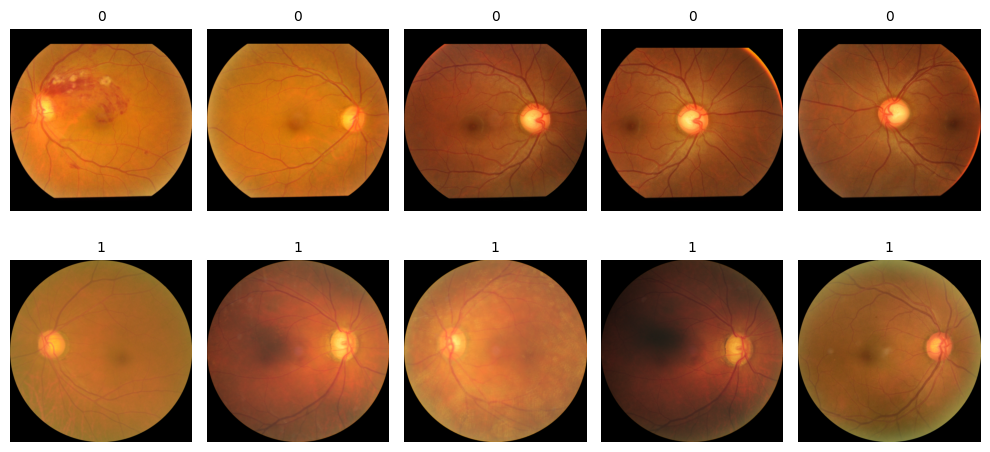

In [6]:
plt.figure(figsize=(10,5))

for i in range(10):
    ax = plt.subplot(2,5, i+1)
    ax.imshow(sample_imgs[i].permute(1,2,0))
    ax.axis('off')
    ax.set_title(sample_labels[i], fontsize=10)

plt.tight_layout()
plt.show()

In [7]:
sample_image = sample_dataset[0][0]
image_shape = sample_image.shape
print(f'Image Shape: {image_shape}')

Image Shape: torch.Size([3, 512, 512])


In [8]:
(torch.min(sample_image), torch.max(sample_image))

(tensor(0.), tensor(1.))

## RGB Image

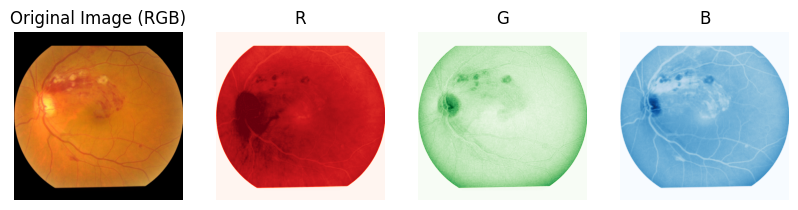

In [9]:
sample_image_np = sample_image.permute(1,2,0).cpu().numpy()
red = sample_image_np[:,:,0]
blue = sample_image_np[:,:,1]
green = sample_image_np[:,:,2]

plt.figure(figsize=(10,4))
plt.subplot(1,4,1)
plt.imshow(sample_image_np)
plt.axis('off')
plt.title('Original Image (RGB)')

plt.subplot(1,4,2)
plt.imshow(red, cmap='Reds')
plt.axis('off')
plt.title('R')

plt.subplot(1,4,3)
plt.imshow(green, cmap="Greens")
plt.axis('off')
plt.title('G')

plt.subplot(1,4,4)
plt.imshow(blue, cmap='Blues')
plt.axis('off')
plt.title('B')

plt.show()

## Ben Graham's Method

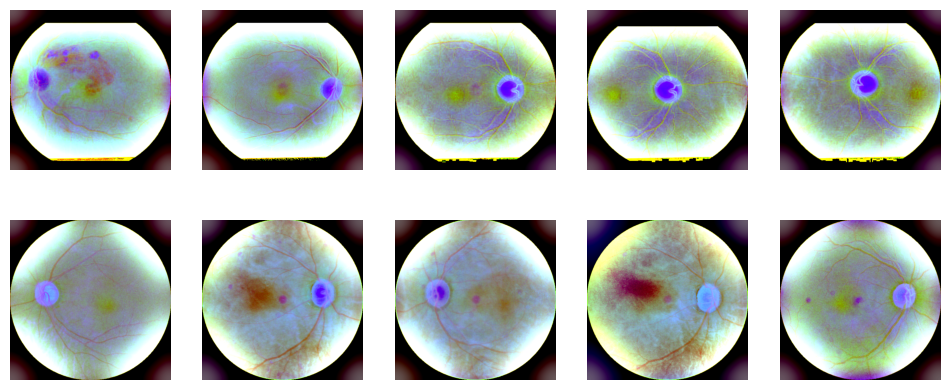

In [10]:
plt.figure(figsize=(12,5))
for i in range(1, len(sample_imgs)+1):
    ax = plt.subplot(2,5,i)
    img_np = sample_imgs[i-1]
    img_np = img_np.cpu().numpy()
    img_np = img_np.transpose(1,2,0)
    img_np = (img_np*255).clip(0,255).astype(np.uint8)
    img_np = cv2.cvtColor(img_np, cv2.COLOR_BGR2HSV)
    img_np = cv2.addWeighted (img_np, 4, cv2.GaussianBlur(img_np, (0,0), 512/10), -4, 128)
    ax.imshow(img_np)
    ax.axis('off')
plt.show()

## Background Subtraction

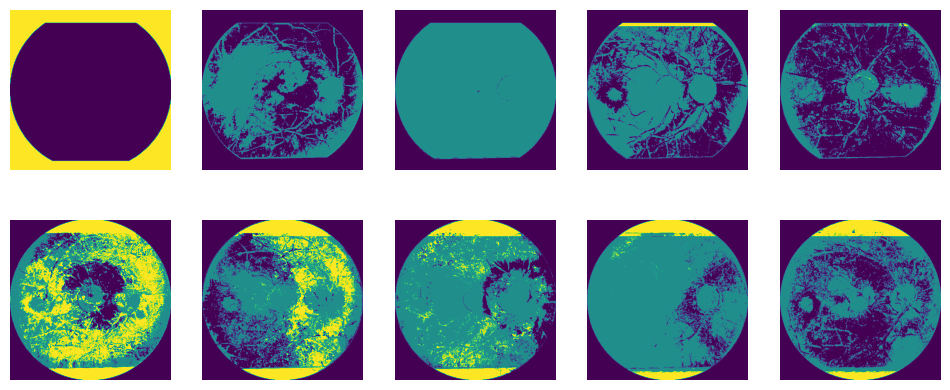

In [11]:
fgbg = cv2.createBackgroundSubtractorMOG2()

plt.figure(figsize=(12,5))
for i in range(1, len(sample_imgs)+1):
    ax = plt.subplot(2,5,i)
    img_np = sample_imgs[i-1]
    img_np = img_np.cpu().numpy()
    img_np = img_np.transpose(1,2,0)
    img_np = (img_np*255).clip(0,255).astype(np.uint8)
    img_np = fgbg.apply(img_np)
    ax.imshow(img_np)
    ax.axis('off')
plt.show()

Background Removal didn't work as expected.

## Fourier Method for Pixel Distribution

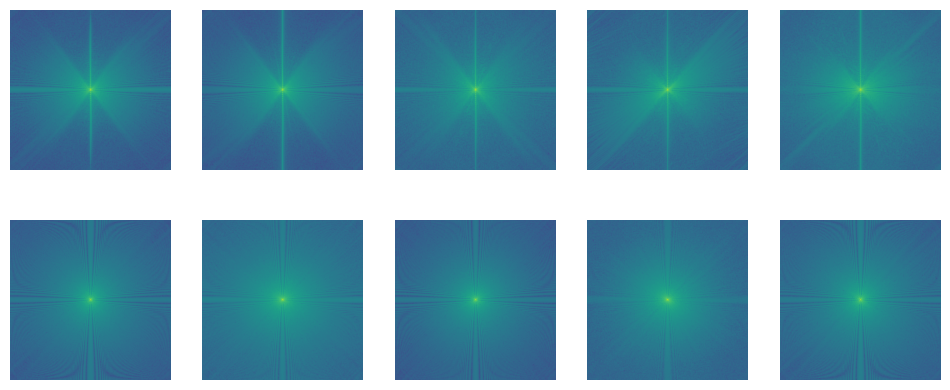

In [12]:
plt.figure(figsize=(12,5))
for i in range(1, len(sample_imgs)+1):
    ax = plt.subplot(2,5,i)
    img_np = sample_imgs[i-1]
    img_np = img_np.cpu().numpy()
    img_np = img_np.transpose(1,2,0)
    img_np = (img_np*255).clip(0,255).astype(np.uint8)
    img_np = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    f = np.fft.fft2(img_np)
    fshift = np.fft.fftshift(f)
    magnitude_spectrum = 20*np.log(np.abs(fshift))
    ax.imshow(magnitude_spectrum)
    ax.axis('off')
plt.show()

## Albumentations

In [13]:
chosen_image = sample_imgs[0].permute(1,2,0).cpu().numpy()
albumentation_list = [A.RandomSunFlare(p=1), 
                      A.RandomFog(p=1,alpha_coef=0.5), 
                      A.RandomBrightnessContrast(brightness_limit=[-0.2,0.2], p=1),
                      A.RandomCrop(p=1,height = 250, width = 250), 
                      A.Rotate(p=1, limit=90),
                      A.RGBShift(p=1), 
                      A.RandomSnow(p=1),
                      A.HorizontalFlip(p=1), 
                      A.VerticalFlip(p=1), 
                      A.RandomBrightnessContrast(contrast_limit=[-0.2,0.2], p=1),
                      A.HueSaturationValue(p=1,hue_shift_limit=20, sat_shift_limit=30, val_shift_limit=50)]

In [14]:
img_matrix_list = []
# img_matrix_list.append(chosen_image)
bboxes_list = []

for aug_type in albumentation_list:
    img = aug_type(image = chosen_image)['image']
    img_matrix_list.append(img)

img_matrix_list.insert(0,chosen_image)    

titles_list = ["Original","RandomSunFlare","RandomFog","RandomBrightness",
               "RandomCrop","Rotate", "RGBShift", "RandomSnow","HorizontalFlip", "VerticalFlip", "RandomContrast","HSV"]

In [15]:
print(type(titles_list[0]))

<class 'str'>


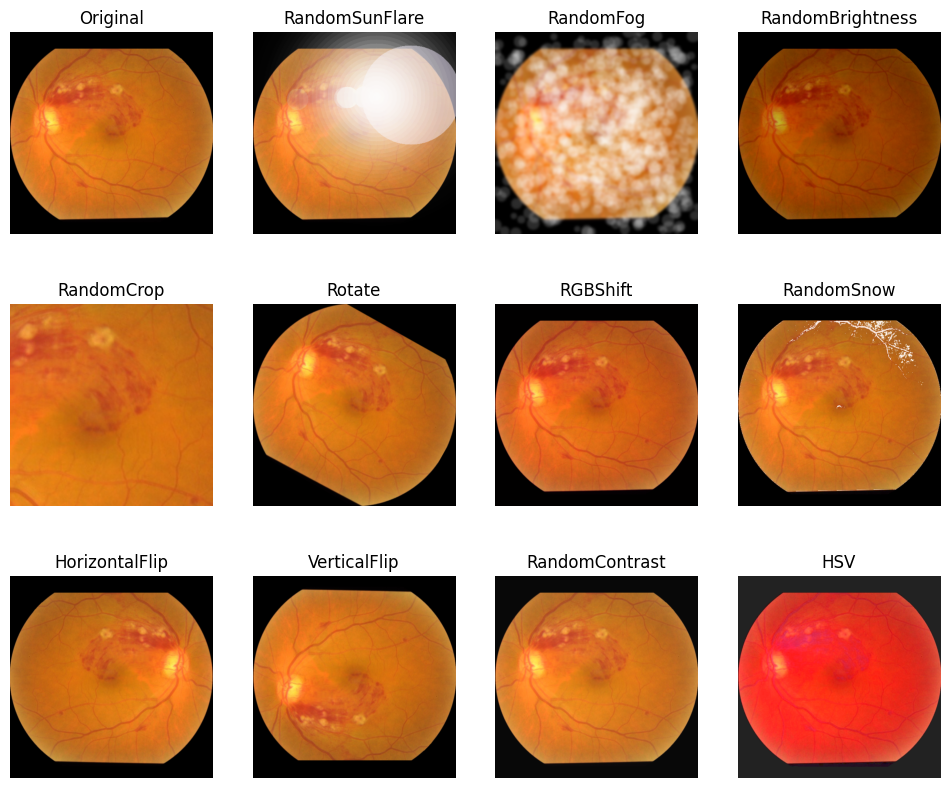

In [16]:
plt.figure(figsize=(12,10))
for i in range(len(img_matrix_list)):
    ax = plt.subplot(3,4,i+1)
    ax.imshow(img_matrix_list[i])
    ax.axis('off')
    ax.set_title(titles_list[i])

plt.show()

## Image Erosion

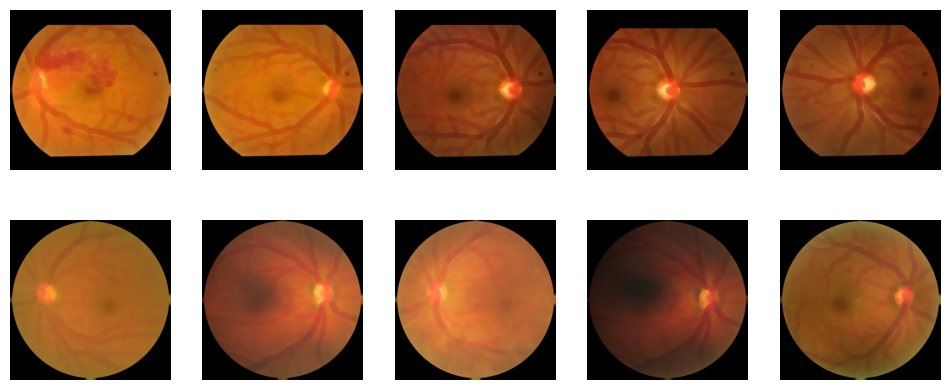

In [17]:
plt.figure(figsize=(12,5))
for i in range(1, len(sample_imgs)+1):
    ax = plt.subplot(2,5,i)
    img_np = sample_imgs[i-1]
    img_np = img_np.cpu().numpy()
    img_np = img_np.transpose(1,2,0)
    img_np = (img_np*255).clip(0,255).astype(np.uint8)
    kernel = np.ones((5,5), np.uint8)
    img_erosion = cv2.erode(img_np, kernel, iterations=3)
    ax.imshow(img_erosion)
    ax.axis('off')
plt.show()

## Image Dilation

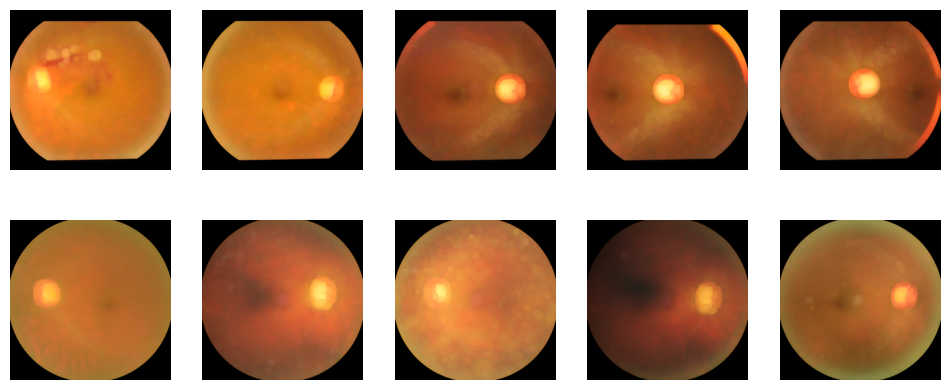

In [18]:
plt.figure(figsize=(12,5))
for i in range(1, len(sample_imgs)+1):
    ax = plt.subplot(2,5,i)
    img_np = sample_imgs[i-1]
    img_np = img_np.cpu().numpy()
    img_np = img_np.transpose(1,2,0)
    img_np = (img_np*255).clip(0,255).astype(np.uint8)
    kernel = np.ones((5,5), np.uint8)
    img_dil = cv2.dilate(img_np, kernel, iterations=3)
    ax.imshow(img_dil)
    ax.axis('off')
plt.show()

## Canny Edge Detection

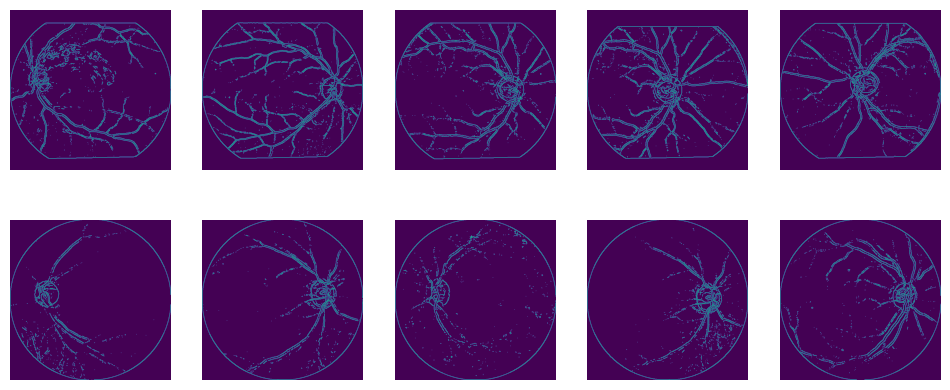

In [19]:
plt.figure(figsize=(12,5))
for i in range(1, len(sample_imgs)+1):
    ax = plt.subplot(2,5,i)
    img_np = sample_imgs[i-1]
    img_np = img_np.cpu().numpy()
    img_np = img_np.transpose(1,2,0)
    img_np = (img_np*255).clip(0,255).astype(np.uint8)
    edges = cv2.Canny(img_np, 50, 50)    
    ax.imshow(edges)
    ax.axis('off')
plt.show()

# Dataset Structure

In [20]:
def print_folder_structure(root_dir):
    file_name = []
    file_count = []

    for root, dirs, files in os.walk(root_dir): # Calculate the depth of the current directory for indentation
        depth = root[len(root_dir):].count(os.sep)
        indent = " " * 4 * depth
        
        # Count all files in the current directory and its subdirectories
        total_files = sum(len(files) for _, _, files in os.walk(root))
        
        print(f"{indent}[{os.path.basename(root)}] - {total_files} files")

        file_name.append(f'{os.path.basename(root)}')
        file_count.append(total_files)
    return file_name, file_count
        

# Define the path to the root dataset directory
dataset_path = "/kaggle/input/gluacoma-dataset/glaucoma_dataset"

# Call the function
print("Folder Structure and File Count:\n")
file_names, file_counts = print_folder_structure(dataset_path)

Folder Structure and File Count:

[glaucoma_dataset] - 17234 files
    [val] - 5747 files
        [0] - 3539 files
        [1] - 2208 files
    [test] - 2866 files
        [0] - 1754 files
        [1] - 1112 files
    [train] - 8621 files
        [0] - 5293 files
        [1] - 3328 files


# File Counts and Implication

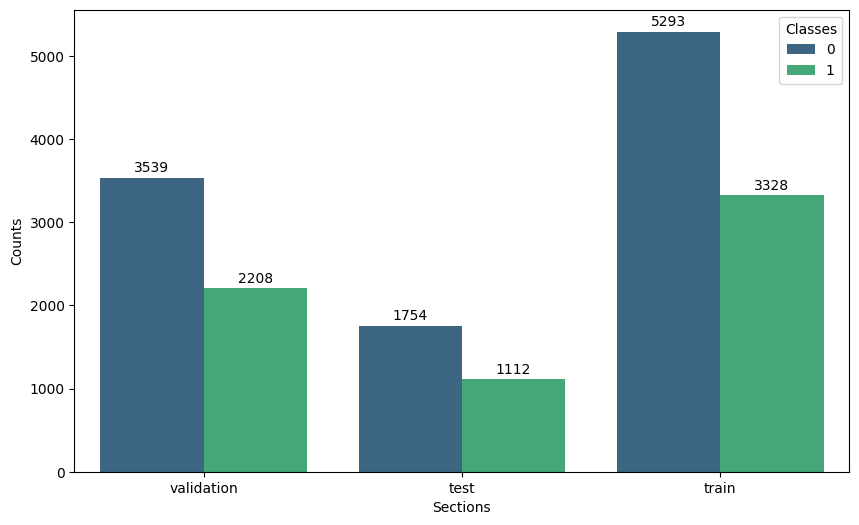

In [21]:
sections = ['validation', 'validation', 'test', 'test', 'train', 'train']
classes = ['0','1','0','1','0','1']
file_numbers = [file_counts[2],file_counts[3],file_counts[5],file_counts[6],file_counts[8],file_counts[9]]
df = pd.DataFrame({
            'Sections': sections,
            'Classes': classes,
            'Counts': file_numbers
            })

plt.figure(figsize=(10,6))
ax = sns.barplot(data=df, x='Sections', y='Counts',hue='Classes', palette='viridis')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge', fontsize=10, padding=2)
    
plt.show()

In [22]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import models, datasets, transforms
from torch import cuda
from tqdm import tqdm  # Import tqdm for progress bar
import matplotlib.pyplot as plt  # For plotting loss and accuracy graphs


# Data Preparation to train ResNet50 model

In [23]:
# Define image size and batch size
IMG_SIZE = (224, 224)
BATCH_SIZE = 32  # Increased batch size

# Data augmentation with additional transformations
train_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load datasets
train_dataset = datasets.ImageFolder(root='/kaggle/input/gluacoma-dataset/glaucoma_dataset/train', transform=train_transform)
val_dataset = datasets.ImageFolder(root='/kaggle/input/gluacoma-dataset/glaucoma_dataset/val', transform=test_transform)

# Data loaders
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Class labels
labels = {v: k for k, v in train_dataset.class_to_idx.items()}
print("Class Labels:", labels)

Class Labels: {0: '0', 1: '1'}


# ResNet50 model

In [24]:
# Check if GPU is available
device = torch.device("cuda" if cuda.is_available() else "cpu")

# Load pre-trained ResNet-50 model
resnet50 = models.resnet50(pretrained=True)

# Unfreeze all layers of ResNet-50
for param in resnet50.parameters():
    param.requires_grad = True  # Allow all layers to be trained

# Modify the final fully connected layer
num_classes = len(train_dataset.classes)
resnet50.fc = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(resnet50.fc.in_features, num_classes)
)

# Move the model to the appropriate device (GPU/CPU)
resnet50 = resnet50.to(device)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 188MB/s] 


In [25]:
print(resnet50)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

# Optimizer with a lower learning rate for fine-tuning

In [26]:
# Optimizer with a lower learning rate for fine-tuning
optimizer = optim.Adam(resnet50.parameters(), lr=0.0001)

# Learning rate scheduler (reduce lr after certain number of epochs)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3, verbose=True)

# Loss function
criterion = nn.CrossEntropyLoss()


# Train the ResNet50 model

In [27]:
# Lists to store the loss and accuracy for plotting
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

# Training loop
num_epochs = 50  # Increased epochs
for epoch in range(num_epochs):
    resnet50.train()  # Set model to training mode
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    # Create a progress bar for the training loop
    with tqdm(train_loader, total=len(train_loader), desc=f"Epoch {epoch+1}/{num_epochs} - Train", unit="batch") as pbar:
        for images, labels in pbar:
            # Move images and labels to the GPU if available
            images, labels = images.to(device), labels.to(device)

            # Zero the gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = resnet50(images)
            
            # Calculate the loss
            loss = criterion(outputs, labels)

            # Backward pass and optimization
            loss.backward()
            optimizer.step()

            # Update the loss and accuracy
            running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            correct_predictions += (predicted == labels).sum().item()
            total_samples += labels.size(0)

            # Update the progress bar with live information
            batch_loss = running_loss / (pbar.n + 1)
            batch_accuracy = (correct_predictions / total_samples) * 100
            pbar.set_postfix(loss=batch_loss, accuracy=batch_accuracy)

    # Calculate training loss and accuracy for this epoch
    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = (correct_predictions / total_samples) * 100
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {epoch_loss:.4f}, Train Accuracy: {epoch_accuracy:.2f}%")

    # Validation loop
    resnet50.eval()  # Set model to evaluation mode
    val_running_loss = 0.0
    val_correct_predictions = 0
    val_total_samples = 0

    # Create a progress bar for the validation loop
    with tqdm(val_loader, total=len(val_loader), desc=f"Epoch {epoch+1}/{num_epochs} - Val", unit="batch") as pbar:
        with torch.no_grad():  # No need to track gradients during validation
            for images, labels in pbar:
                images, labels = images.to(device), labels.to(device)

                # Forward pass
                outputs = resnet50(images)

                # Calculate the loss
                loss = criterion(outputs, labels)
                val_running_loss += loss.item()

                # Calculate accuracy
                _, predicted = torch.max(outputs, 1)
                val_correct_predictions += (predicted == labels).sum().item()
                val_total_samples += labels.size(0)

                # Update the progress bar with live information
                batch_loss = val_running_loss / (pbar.n + 1)
                batch_accuracy = (val_correct_predictions / val_total_samples) * 100
                pbar.set_postfix(loss=batch_loss, accuracy=batch_accuracy)

    # Calculate validation loss and accuracy for this epoch
    val_loss = val_running_loss / len(val_loader)
    val_accuracy = (val_correct_predictions / val_total_samples) * 100
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(f"Epoch [{epoch+1}/{num_epochs}], Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.2f}%")

    # Update learning rate scheduler
    scheduler.step(val_loss)

Epoch 1/50 - Train: 100%|██████████| 270/270 [04:38<00:00,  1.03s/batch, accuracy=78.1, loss=0.474]


Epoch [1/50], Train Loss: 0.4743, Train Accuracy: 78.10%


Epoch 1/50 - Val: 100%|██████████| 180/180 [02:05<00:00,  1.43batch/s, accuracy=86.8, loss=0.318]


Epoch [1/50], Val Loss: 0.3179, Val Accuracy: 86.85%


Epoch 2/50 - Train: 100%|██████████| 270/270 [03:44<00:00,  1.20batch/s, accuracy=83.3, loss=0.383]


...

Epoch [49/50], Val Loss: 0.0966, Val Accuracy: 95.82%


Epoch 50/50 - Train: 100%|██████████| 270/270 [03:26<00:00,  1.31batch/s, accuracy=94.7, loss=0.131]


Epoch [50/50], Train Loss: 0.1310, Train Accuracy: 94.70%


Epoch 50/50 - Val: 100%|██████████| 180/180 [01:20<00:00,  2.25batch/s, accuracy=95.8, loss=0.0983]

Epoch [50/50], Val Loss: 0.0983, Val Accuracy: 95.75%


## Plot training and validation loss

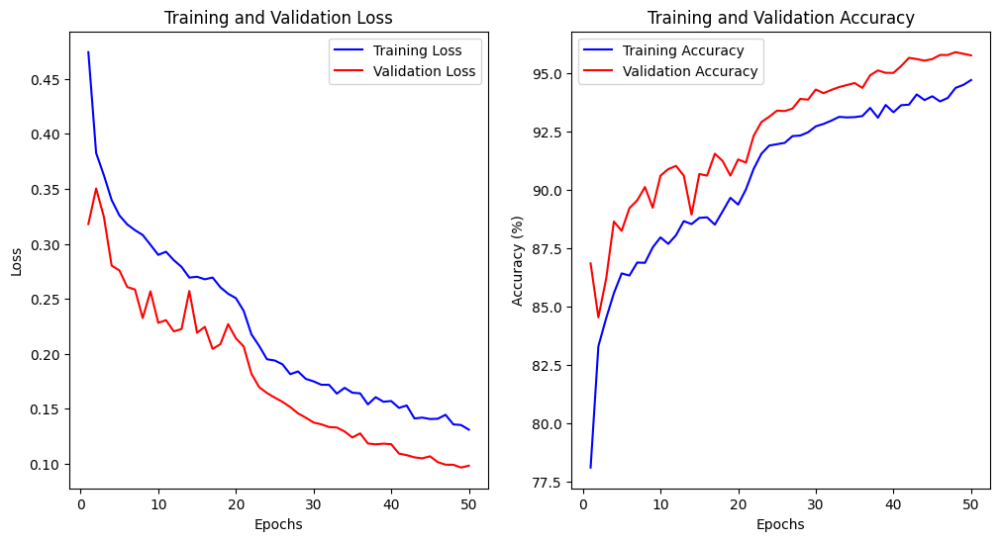

In [28]:
# Plot training and validation loss
plt.figure(figsize=(12, 6))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(range(1, num_epochs + 1), train_losses, label='Training Loss', color='blue')
plt.plot(range(1, num_epochs + 1), val_losses, label='Validation Loss', color='red')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(range(1, num_epochs + 1), train_accuracies, label='Training Accuracy', color='blue')
plt.plot(range(1, num_epochs + 1), val_accuracies, label='Validation Accuracy', color='red')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.show()

# Save the Trained ResNet50 model

In [29]:
# Save the trained model's state dictionary, along with additional information if needed
save_path = 'resnet50_final.pth'
torch.save({
    'epoch': num_epochs,
    'model_state_dict': resnet50.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'train_losses': train_losses,
    'val_losses': val_losses,
    'train_accuracies': train_accuracies,
    'val_accuracies': val_accuracies,
}, save_path)

print(f"Model saved to {save_path}")

Model saved to resnet50_final.pth


# Compute metrics and confusion matrix on test dataset for ResNet50 model

Test Accuracy: 0.9574
Test Precision: 0.9586
Test Recall: 0.9574
Test F1 Score: 0.9571

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.99      0.97      1754
           1       0.98      0.91      0.94      1112

    accuracy                           0.96      2866
   macro avg       0.96      0.95      0.95      2866
weighted avg       0.96      0.96      0.96      2866



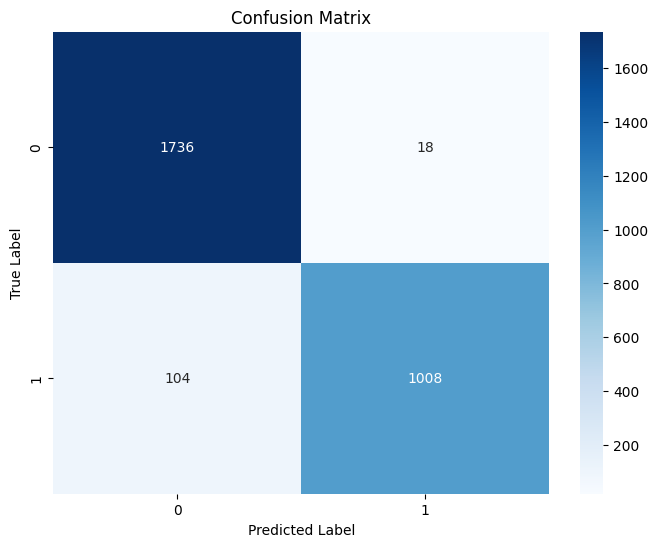

In [30]:
import numpy as np
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Define the test dataset and test_loader if not already defined
test_dataset = datasets.ImageFolder(root='/kaggle/input/gluacoma-dataset/glaucoma_dataset/test', transform=test_transform)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Set the model to evaluation mode
resnet50.eval()

all_labels = []
all_preds = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = resnet50(images)
        _, preds = torch.max(outputs, 1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

# Convert lists to numpy arrays
all_labels = np.array(all_labels)
all_preds = np.array(all_preds)

# Compute metrics
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds, average="weighted")
recall = recall_score(all_labels, all_preds, average="weighted")
f1 = f1_score(all_labels, all_preds, average="weighted")
conf_mat = confusion_matrix(all_labels, all_preds)
class_report = classification_report(all_labels, all_preds)

print("Test Accuracy: {:.4f}".format(accuracy))
print("Test Precision: {:.4f}".format(precision))
print("Test Recall: {:.4f}".format(recall))
print("Test F1 Score: {:.4f}".format(f1))
print("\nClassification Report:\n", class_report)

# Plot the confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

# Give the unseen Image as a input to predict the output using ResNet50 model

**It will predict whether image is Gluacoma or No Gluacoma**

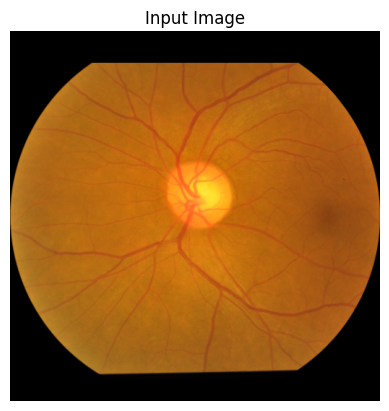

Prediction: No Glaucoma


In [31]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Define the test transform (should be the same as used during evaluation)
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

# Load an unseen image (update the path accordingly)
img_path = '/kaggle/input/gluacoma-dataset/glaucoma_dataset/test/0/BEH-192.png'  # Replace with your image path
img = Image.open(img_path).convert("RGB")
plt.imshow(img)
plt.title("Input Image")
plt.axis("off")
plt.show()

# Apply the transform and add a batch dimension
img_tensor = test_transform(img).unsqueeze(0).to(device)

# Recreate the model architecture (must match what was used for training)
num_classes = 2  # Adjust based on your dataset (e.g., 2 for Glaucoma vs No Glaucoma)
resnet50 = models.resnet50(pretrained=False)
resnet50.fc = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(resnet50.fc.in_features, num_classes)
)
resnet50 = resnet50.to(device)

# Load the saved model state dictionary
model_path = '/kaggle/input/gluacoma/pytorch/default/1/resnet50_final.pth'
checkpoint = torch.load(model_path, map_location=device)
resnet50.load_state_dict(checkpoint['model_state_dict'])
resnet50.eval()

# Make a prediction
with torch.no_grad():
    outputs = resnet50(img_tensor)
    _, predicted = torch.max(outputs, 1)

# Define your class mapping (update as needed)
class_mapping = {0: "No Glaucoma", 1: "Glaucoma"}
prediction_label = class_mapping[predicted.item()]

print("Prediction:", prediction_label)

# Data Preparation for ResNet18 model

In [32]:
# Define image size and batch size
IMG_SIZE = (224, 224)
BATCH_SIZE = 32  # Increased batch size

# Data augmentation with additional transformations
train_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load datasets
train_dataset = datasets.ImageFolder(root='/kaggle/input/gluacoma-dataset/glaucoma_dataset/train', transform=train_transform)
val_dataset = datasets.ImageFolder(root='/kaggle/input/gluacoma-dataset/glaucoma_dataset/val', transform=test_transform)

# Data loaders
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Class labels
labels = {v: k for k, v in train_dataset.class_to_idx.items()}
print("Class Labels:", labels)

Class Labels: {0: '0', 1: '1'}


# ResNet18 Model

In [33]:
# Check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pre-trained ResNet-18 model
resnet18 = models.resnet18(pretrained=True)

# Unfreeze all layers of ResNet-18 (allowing fine-tuning)
for param in resnet18.parameters():
    param.requires_grad = True

# Modify the final fully connected layer for our number of classes
num_classes = len(train_dataset.classes)
resnet18.fc = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(resnet18.fc.in_features, num_classes)
)

# Move the model to the appropriate device (GPU/CPU)
resnet18 = resnet18.to(device)
print(resnet18)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 174MB/s] 


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [34]:
# Define the optimizer with a lower learning rate for fine-tuning
optimizer = optim.Adam(resnet18.parameters(), lr=0.0001)

# Define a learning rate scheduler (reduces lr when validation loss plateaus)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3, verbose=True)

# Loss function
criterion = nn.CrossEntropyLoss()

# Train the ResNet18 Model

In [35]:
# Lists to store the loss and accuracy for plotting
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

# Training loop
num_epochs = 50  # Increased epochs
for epoch in range(num_epochs):
    resnet18.train()  # Set model to training mode
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    # Training progress bar
    with tqdm(train_loader, total=len(train_loader), desc=f"Epoch {epoch+1}/{num_epochs} - Train", unit="batch") as pbar:
        for images, labels in pbar:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()  # Zero the gradients

            outputs = resnet18(images)  # Forward pass
            loss = criterion(outputs, labels)  # Compute loss

            loss.backward()  # Backward pass
            optimizer.step()  # Update weights

            running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            correct_predictions += (predicted == labels).sum().item()
            total_samples += labels.size(0)

            # Update progress bar with current loss and accuracy
            batch_loss = running_loss / (pbar.n + 1)
            batch_accuracy = (correct_predictions / total_samples) * 100
            pbar.set_postfix(loss=batch_loss, accuracy=batch_accuracy)

    # Calculate and log epoch training metrics
    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = (correct_predictions / total_samples) * 100
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)
    print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {epoch_loss:.4f}, Train Accuracy: {epoch_accuracy:.2f}%")

    # Validation loop
    resnet18.eval()  # Set model to evaluation mode
    val_running_loss = 0.0
    val_correct_predictions = 0
    val_total_samples = 0

    with tqdm(val_loader, total=len(val_loader), desc=f"Epoch {epoch+1}/{num_epochs} - Val", unit="batch") as pbar:
        with torch.no_grad():
            for images, labels in pbar:
                images, labels = images.to(device), labels.to(device)
                outputs = resnet18(images)
                loss = criterion(outputs, labels)
                val_running_loss += loss.item()

                _, predicted = torch.max(outputs, 1)
                val_correct_predictions += (predicted == labels).sum().item()
                val_total_samples += labels.size(0)

                batch_loss = val_running_loss / (pbar.n + 1)
                batch_accuracy = (val_correct_predictions / val_total_samples) * 100
                pbar.set_postfix(loss=batch_loss, accuracy=batch_accuracy)

    # Calculate and log epoch validation metrics
    val_loss = val_running_loss / len(val_loader)
    val_accuracy = (val_correct_predictions / val_total_samples) * 100
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)
    print(f"Epoch [{epoch+1}/{num_epochs}], Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.2f}%")

    # Update learning rate based on validation loss
    scheduler.step(val_loss)

Epoch 1/50 - Train: 100%|██████████| 270/270 [02:57<00:00,  1.52batch/s, accuracy=76.5, loss=0.512]


Epoch [1/50], Train Loss: 0.5118, Train Accuracy: 76.52%


Epoch 1/50 - Val: 100%|██████████| 180/180 [01:13<00:00,  2.47batch/s, accuracy=85.6, loss=0.338]


Epoch [1/50], Val Loss: 0.3384, Val Accuracy: 85.58%


Epoch 2/50 - Train: 100%|██████████| 270/270 [02:56<00:00,  1.53batch/s, accuracy=82.2, loss=0.416]


...

Epoch [49/50], Val Loss: 0.1083, Val Accuracy: 95.34%


Epoch 50/50 - Train: 100%|██████████| 270/270 [02:57<00:00,  1.52batch/s, accuracy=93.4, loss=0.164]


Epoch [50/50], Train Loss: 0.1642, Train Accuracy: 93.42%


Epoch 50/50 - Val: 100%|██████████| 180/180 [01:12<00:00,  2.50batch/s, accuracy=95.6, loss=0.109] 

Epoch [50/50], Val Loss: 0.1088, Val Accuracy: 95.56%


## Plot training and validation loss

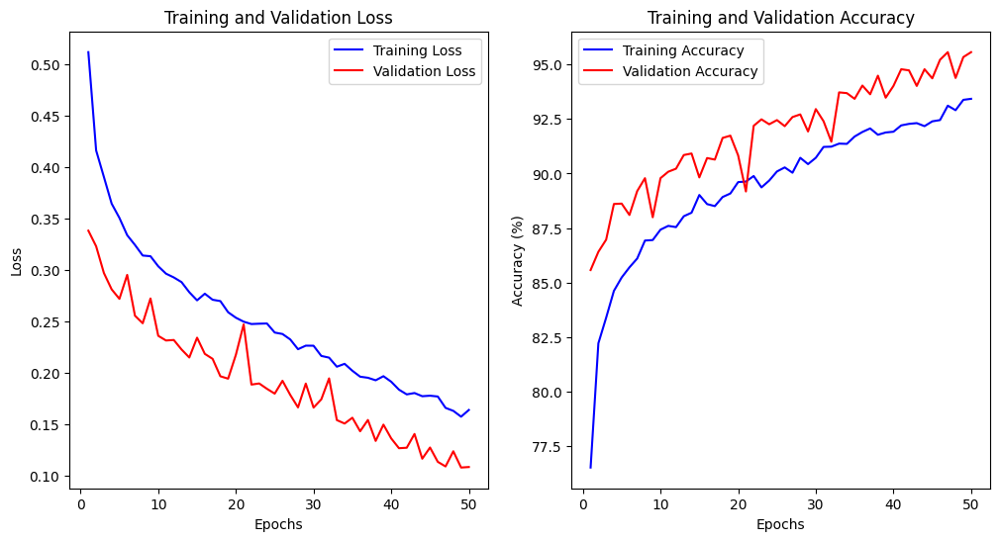

In [36]:
# Plot training and validation loss and accuracy
plt.figure(figsize=(12, 6))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(range(1, num_epochs + 1), train_losses, label='Training Loss', color='blue')
plt.plot(range(1, num_epochs + 1), val_losses, label='Validation Loss', color='red')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(range(1, num_epochs + 1), train_accuracies, label='Training Accuracy', color='blue')
plt.plot(range(1, num_epochs + 1), val_accuracies, label='Validation Accuracy', color='red')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.show()

# Save the Trained ResNet18 Model

In [37]:
# Save the trained model's state dictionary and additional training information
save_path = 'resnet18_final.pth'
torch.save({
    'epoch': num_epochs,
    'model_state_dict': resnet18.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'train_losses': train_losses,
    'val_losses': val_losses,
    'train_accuracies': train_accuracies,
    'val_accuracies': val_accuracies,
}, save_path)
print(f"Model saved to {save_path}")

Model saved to resnet18_final.pth


# Compute metrics and confusion matrix on test dataset for ResNet18 model

Test Accuracy: 0.9560
Test Precision: 0.9568
Test Recall: 0.9560
Test F1 Score: 0.9557

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.99      0.96      1754
           1       0.97      0.91      0.94      1112

    accuracy                           0.96      2866
   macro avg       0.96      0.95      0.95      2866
weighted avg       0.96      0.96      0.96      2866



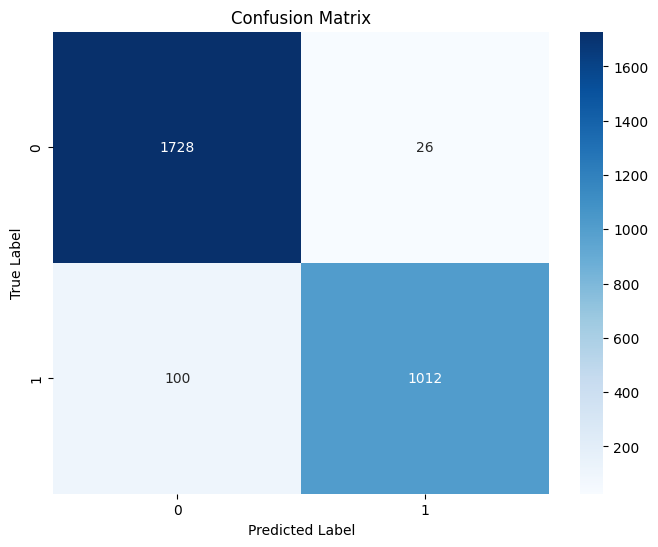

In [38]:
# Testing the model
test_dataset = datasets.ImageFolder(root='/kaggle/input/gluacoma-dataset/glaucoma_dataset/test', transform=test_transform)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

resnet18.eval()
all_labels = []
all_preds = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = resnet18(images)
        _, preds = torch.max(outputs, 1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

all_labels = np.array(all_labels)
all_preds = np.array(all_preds)

# Compute evaluation metrics
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds, average="weighted")
recall = recall_score(all_labels, all_preds, average="weighted")
f1 = f1_score(all_labels, all_preds, average="weighted")
conf_mat = confusion_matrix(all_labels, all_preds)
class_report = classification_report(all_labels, all_preds)

print("Test Accuracy: {:.4f}".format(accuracy))
print("Test Precision: {:.4f}".format(precision))
print("Test Recall: {:.4f}".format(recall))
print("Test F1 Score: {:.4f}".format(f1))
print("\nClassification Report:\n", class_report)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

# Data Preparation to train VGG19 model

In [12]:
# Define image size and batch size
IMG_SIZE = (224, 224)
BATCH_SIZE = 32  # Increased batch size

# Data augmentation with additional transformations for training
train_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Transformations for testing/validation
test_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Load full datasets
train_dataset = datasets.ImageFolder(root='/kaggle/input/gluacoma-dataset/glaucoma_dataset/train', transform=train_transform)
val_dataset = datasets.ImageFolder(root='/kaggle/input/gluacoma-dataset/glaucoma_dataset/val', transform=test_transform)

# Define how many samples to take (modify these numbers as needed)
num_train_samples = 2000  # e.g., take 1000 images for training
num_val_samples = 1000     # e.g., take 200 images for validation

# Randomly select indices from the datasets
train_indices = torch.randperm(len(train_dataset))[:num_train_samples].tolist()
val_indices = torch.randperm(len(val_dataset))[:num_val_samples].tolist()

# Create subsets of the datasets
train_subset = torch.utils.data.Subset(train_dataset, train_indices)
val_subset = torch.utils.data.Subset(val_dataset, val_indices)

# Data loaders using the subsets
train_loader = torch.utils.data.DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False)

# Class labels mapping remains the same
labels = {v: k for k, v in train_dataset.class_to_idx.items()}
print("Class Labels:", labels)

Class Labels: {0: '0', 1: '1'}


# VGG19 Model

In [13]:
# Check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pre-trained VGG19 model
vgg19 = models.vgg19(pretrained=True)

# Unfreeze all layers (for fine-tuning)
for param in vgg19.parameters():
    param.requires_grad = True

# Modify the classifier to match the number of classes
# Here we replace the final layer of the classifier
num_features = vgg19.classifier[6].in_features
vgg19.classifier[6] = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(num_features, len(train_dataset.classes))
)

# Move the model to the appropriate device (GPU/CPU)
vgg19 = vgg19.to(device)
print(vgg19)

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padd

In [14]:
# Define optimizer with a lower learning rate for fine-tuning
optimizer = optim.Adam(vgg19.parameters(), lr=0.0001)

# Learning rate scheduler (reduce lr after certain number of epochs if plateau)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3, verbose=True)

# Loss function
criterion = nn.CrossEntropyLoss()

# Trqin the VGG19 Model

In [15]:
# Lists to store loss and accuracy values for plotting
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

# Training loop
num_epochs = 50  # Increased epochs
for epoch in range(num_epochs):
    vgg19.train()  # Set model to training mode
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    # Training progress bar
    with tqdm(train_loader, total=len(train_loader), desc=f"Epoch {epoch+1}/{num_epochs} - Train", unit="batch") as pbar:
        for images, targets in pbar:
            images, targets = images.to(device), targets.to(device)
            optimizer.zero_grad()  # Zero gradients

            outputs = vgg19(images)  # Forward pass
            loss = criterion(outputs, targets)  # Compute loss

            loss.backward()  # Backward pass
            optimizer.step()  # Update weights

            running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            correct_predictions += (predicted == targets).sum().item()
            total_samples += targets.size(0)

            # Update progress bar with live metrics
            batch_loss = running_loss / (pbar.n + 1)
            batch_accuracy = (correct_predictions / total_samples) * 100
            pbar.set_postfix(loss=batch_loss, accuracy=batch_accuracy)

    # Calculate training metrics for the epoch
    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = (correct_predictions / total_samples) * 100
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)
    print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {epoch_loss:.4f}, Train Accuracy: {epoch_accuracy:.2f}%")

    # Validation loop
    vgg19.eval()  # Set model to evaluation mode
    val_running_loss = 0.0
    val_correct_predictions = 0
    val_total_samples = 0

    with tqdm(val_loader, total=len(val_loader), desc=f"Epoch {epoch+1}/{num_epochs} - Val", unit="batch") as pbar:
        with torch.no_grad():
            for images, targets in pbar:
                images, targets = images.to(device), targets.to(device)
                outputs = vgg19(images)
                loss = criterion(outputs, targets)
                val_running_loss += loss.item()

                _, predicted = torch.max(outputs, 1)
                val_correct_predictions += (predicted == targets).sum().item()
                val_total_samples += targets.size(0)

                batch_loss = val_running_loss / (pbar.n + 1)
                batch_accuracy = (val_correct_predictions / val_total_samples) * 100
                pbar.set_postfix(loss=batch_loss, accuracy=batch_accuracy)

    # Calculate validation metrics for the epoch
    val_loss = val_running_loss / len(val_loader)
    val_accuracy = (val_correct_predictions / val_total_samples) * 100
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)
    print(f"Epoch [{epoch+1}/{num_epochs}], Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.2f}%")

    # Update the learning rate scheduler
    scheduler.step(val_loss)

Epoch 1/50 - Train: 100%|██████████| 63/63 [00:54<00:00,  1.16batch/s, accuracy=61.7, loss=0.668]


Epoch [1/50], Train Loss: 0.6680, Train Accuracy: 61.70%


Epoch 1/50 - Val: 100%|██████████| 32/32 [00:14<00:00,  2.20batch/s, accuracy=69.8, loss=0.574]


Epoch [1/50], Val Loss: 0.5742, Val Accuracy: 69.80%


Epoch 2/50 - Train: 100%|██████████| 63/63 [00:53<00:00,  1.17batch/s, accuracy=70.2, loss=0.58] 


...

Epoch [49/50], Val Loss: 0.3129, Val Accuracy: 87.50%


Epoch 50/50 - Train: 100%|██████████| 63/63 [00:54<00:00,  1.16batch/s, accuracy=88.6, loss=0.259]


Epoch [50/50], Train Loss: 0.2585, Train Accuracy: 88.65%


Epoch 50/50 - Val: 100%|██████████| 32/32 [00:14<00:00,  2.18batch/s, accuracy=87.5, loss=0.313]

Epoch [50/50], Val Loss: 0.3129, Val Accuracy: 87.50%


## Plot training and validation loss

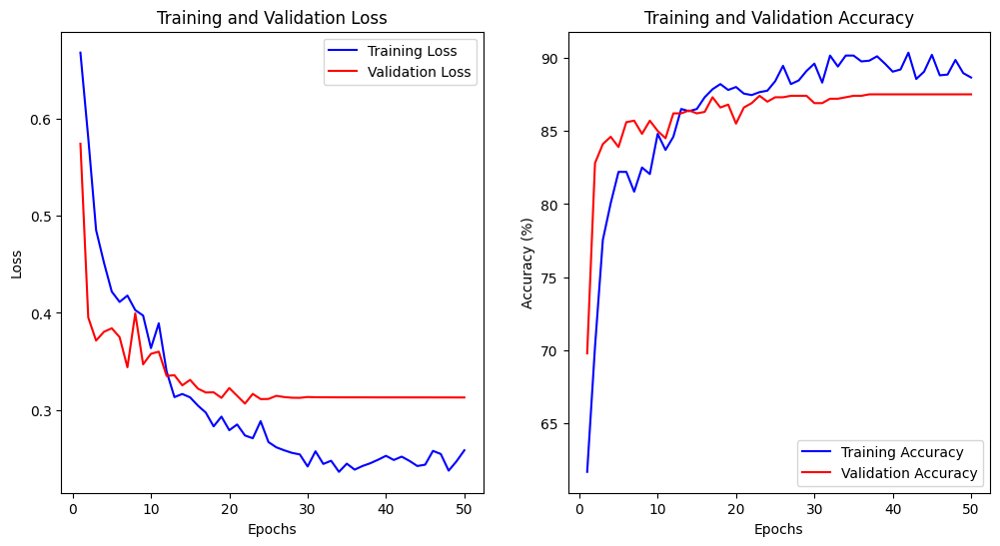

In [16]:
# Plot training and validation loss and accuracy
plt.figure(figsize=(12, 6))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(range(1, num_epochs + 1), train_losses, label='Training Loss', color='blue')
plt.plot(range(1, num_epochs + 1), val_losses, label='Validation Loss', color='red')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(range(1, num_epochs + 1), train_accuracies, label='Training Accuracy', color='blue')
plt.plot(range(1, num_epochs + 1), val_accuracies, label='Validation Accuracy', color='red')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.show()

# Save the Trained VGG19 Model

In [17]:
# Save the trained model's state dictionary and additional information
save_path = 'vgg19_final.pth'
torch.save({
    'epoch': num_epochs,
    'model_state_dict': vgg19.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'train_losses': train_losses,
    'val_losses': val_losses,
    'train_accuracies': train_accuracies,
    'val_accuracies': val_accuracies,
}, save_path)
print(f"Model saved to {save_path}")

Model saved to vgg19_final.pth


# Compute metrics and confusion matrix on test dataset for VGG19 model

Test Accuracy: 0.8660
Test Precision: 0.8655
Test Recall: 0.8660
Test F1 Score: 0.8657

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.90      0.89      1754
           1       0.84      0.81      0.83      1112

    accuracy                           0.87      2866
   macro avg       0.86      0.86      0.86      2866
weighted avg       0.87      0.87      0.87      2866



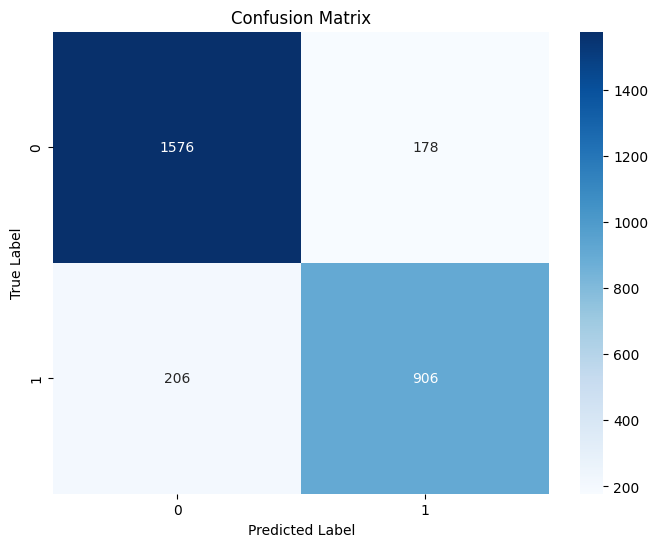

In [18]:
# Testing the model
test_dataset = datasets.ImageFolder(root='/kaggle/input/gluacoma-dataset/glaucoma_dataset/test', transform=test_transform)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

vgg19.eval()
all_labels = []
all_preds = []

with torch.no_grad():
    for images, targets in test_loader:
        images, targets = images.to(device), targets.to(device)
        outputs = vgg19(images)
        _, preds = torch.max(outputs, 1)
        all_labels.extend(targets.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

all_labels = np.array(all_labels)
all_preds = np.array(all_preds)

# Compute evaluation metrics
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds, average="weighted")
recall = recall_score(all_labels, all_preds, average="weighted")
f1 = f1_score(all_labels, all_preds, average="weighted")
conf_mat = confusion_matrix(all_labels, all_preds)
class_report = classification_report(all_labels, all_preds)

print("Test Accuracy: {:.4f}".format(accuracy))
print("Test Precision: {:.4f}".format(precision))
print("Test Recall: {:.4f}".format(recall))
print("Test F1 Score: {:.4f}".format(f1))
print("\nClassification Report:\n", class_report)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

# Data Preparation to train InceptionV3 model

In [25]:
# Define image size for InceptionV3
IMG_SIZE = (299, 299)
BATCH_SIZE = 32

# Data augmentation
train_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
    transforms.RandomResizedCrop(299, scale=(0.8, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.CenterCrop(299),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Load full datasets
train_dataset = datasets.ImageFolder(root='/kaggle/input/gluacoma-dataset/glaucoma_dataset/train', transform=train_transform)
val_dataset = datasets.ImageFolder(root='/kaggle/input/gluacoma-dataset/glaucoma_dataset/val', transform=test_transform)

# Define how many samples to take (modify these numbers as needed)
num_train_samples = 2000  # e.g., take 1000 images for training
num_val_samples = 1000     # e.g., take 200 images for validation

# Randomly select indices from the datasets
train_indices = torch.randperm(len(train_dataset))[:num_train_samples].tolist()
val_indices = torch.randperm(len(val_dataset))[:num_val_samples].tolist()

# Create subsets of the datasets
train_subset = torch.utils.data.Subset(train_dataset, train_indices)
val_subset = torch.utils.data.Subset(val_dataset, val_indices)

# Data loaders using the subsets
train_loader = torch.utils.data.DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False)

# Class labels mapping remains the same
labels = {v: k for k, v in train_dataset.class_to_idx.items()}
print("Class Labels:", labels)

Class Labels: {0: '0', 1: '1'}


# InceptionV3 Model

In [26]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained InceptionV3
inception = models.inception_v3(pretrained=True, aux_logits=True)
num_classes = len(train_dataset.classes)

# Replace final layers (both aux and main classifiers)
inception.AuxLogits.fc = nn.Linear(inception.AuxLogits.fc.in_features, num_classes)
inception.fc = nn.Linear(inception.fc.in_features, num_classes)

inception = inception.to(device)
print(inception)
# Unfreeze all layers for fine-tuning
for param in inception.parameters():
    param.requires_grad = True

# Optimizer & Scheduler
optimizer = optim.Adam(inception.parameters(), lr=0.0001)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3, verbose=True)
criterion = nn.CrossEntropyLoss()

Inception3(
  (Conv2d_1a_3x3): BasicConv2d(
    (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
    (bn): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_2a_3x3): BasicConv2d(
    (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_2b_3x3): BasicConv2d(
    (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn): BatchNorm2d(64, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (maxpool1): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (Conv2d_3b_1x1): BasicConv2d(
    (conv): Conv2d(64, 80, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(80, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_4a_3x3): BasicConv2d(
    (conv): Conv2d(80, 192, kernel_size=(3, 3), stri

# Train the InceptionV3 Model

In [27]:
# Lists for plotting
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

# Training loop
num_epochs = 50

for epoch in range(num_epochs):
    inception.train()
    running_loss = 0.0
    correct = 0
    total = 0

    with tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Train", unit="batch") as pbar:
        for images, targets in pbar:
            images, targets = images.to(device), targets.to(device)

            optimizer.zero_grad()
            outputs, aux_outputs = inception(images)

            loss1 = criterion(outputs, targets)
            loss2 = criterion(aux_outputs, targets)
            loss = loss1 + 0.4 * loss2

            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == targets).sum().item()
            total += targets.size(0)

            pbar.set_postfix(loss=running_loss / (pbar.n + 1), accuracy=(correct / total) * 100)

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = (correct / total) * 100
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)
    print(f"Epoch [{epoch+1}/{num_epochs}] Train Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.2f}%")

    # Validation
    inception.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Val", unit="batch") as pbar:
        with torch.no_grad():
            for images, targets in pbar:
                images, targets = images.to(device), targets.to(device)
                outputs = inception(images)

                loss = criterion(outputs, targets)
                val_loss += loss.item()

                _, predicted = torch.max(outputs, 1)
                val_correct += (predicted == targets).sum().item()
                val_total += targets.size(0)

                pbar.set_postfix(loss=val_loss / (pbar.n + 1), accuracy=(val_correct / val_total) * 100)

    val_epoch_loss = val_loss / len(val_loader)
    val_epoch_acc = (val_correct / val_total) * 100
    val_losses.append(val_epoch_loss)
    val_accuracies.append(val_epoch_acc)

    print(f"Epoch [{epoch+1}/{num_epochs}] Val Loss: {val_epoch_loss:.4f}, Accuracy: {val_epoch_acc:.2f}%")
    scheduler.step(val_epoch_loss)

Epoch 1/50 - Train: 100%|██████████| 63/63 [01:05<00:00,  1.03s/batch, accuracy=73.2, loss=0.733]


Epoch [1/50] Train Loss: 0.7331, Accuracy: 73.20%


Epoch 1/50 - Val: 100%|██████████| 32/32 [00:15<00:00,  2.01batch/s, accuracy=76.4, loss=0.46] 


Epoch [1/50] Val Loss: 0.4602, Accuracy: 76.40%


Epoch 2/50 - Train: 100%|██████████| 63/63 [01:05<00:00,  1.03s/batch, accuracy=81.5, loss=0.583]


...

Epoch [49/50] Val Loss: 0.3280, Accuracy: 88.20%


Epoch 50/50 - Train: 100%|██████████| 63/63 [01:05<00:00,  1.03s/batch, accuracy=94.7, loss=0.199]


Epoch [50/50] Train Loss: 0.1995, Accuracy: 94.70%


Epoch 50/50 - Val: 100%|██████████| 32/32 [00:15<00:00,  2.01batch/s, accuracy=87.9, loss=0.322]

Epoch [50/50] Val Loss: 0.3225, Accuracy: 87.90%


## Plot training and validation loss

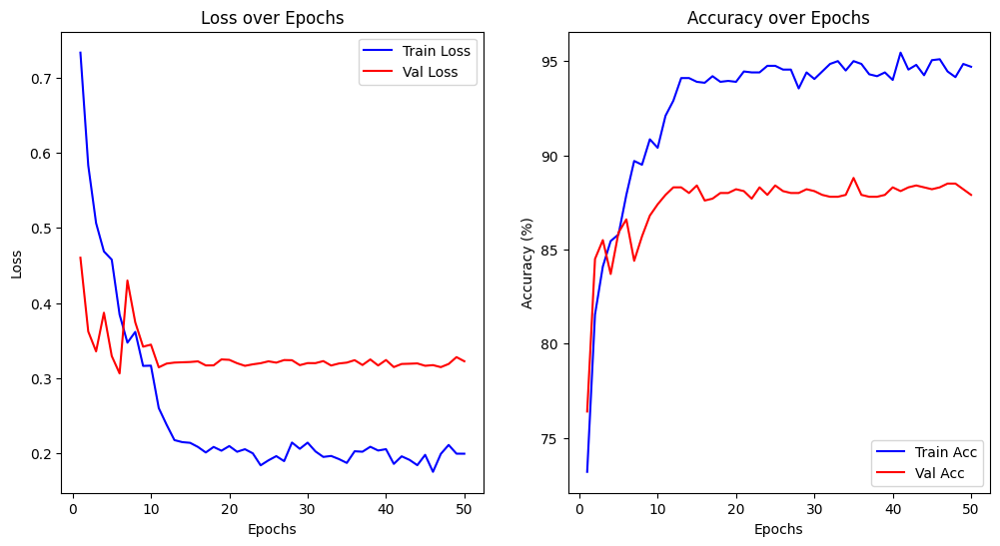

In [28]:
# Plot training/validation curves
plt.figure(figsize=(12, 6))

# Loss
plt.subplot(1, 2, 1)
plt.plot(range(1, num_epochs + 1), train_losses, label="Train Loss", color='blue')
plt.plot(range(1, num_epochs + 1), val_losses, label="Val Loss", color='red')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss over Epochs")
plt.legend()

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(range(1, num_epochs + 1), train_accuracies, label="Train Acc", color='blue')
plt.plot(range(1, num_epochs + 1), val_accuracies, label="Val Acc", color='red')
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy over Epochs")
plt.legend()

plt.show()

# Save the Trained InceptionV3 Model

In [29]:
# Save the model
torch.save({
    'epoch': num_epochs,
    'model_state_dict': inception.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'train_losses': train_losses,
    'val_losses': val_losses,
    'train_accuracies': train_accuracies,
    'val_accuracies': val_accuracies,
}, "inceptionv3_final.pth")

print("Model saved as inceptionv3_final.pth")

Model saved as inceptionv3_final.pth


# Compute metrics and confusion matrix on test dataset for InceptionV3 model

Test Accuracy: 0.8921842288904397
Precision: 0.8918635571155736
Recall: 0.8921842288904397
F1 Score: 0.8919528204107274

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.92      0.91      1754
           1       0.87      0.85      0.86      1112

    accuracy                           0.89      2866
   macro avg       0.89      0.88      0.89      2866
weighted avg       0.89      0.89      0.89      2866



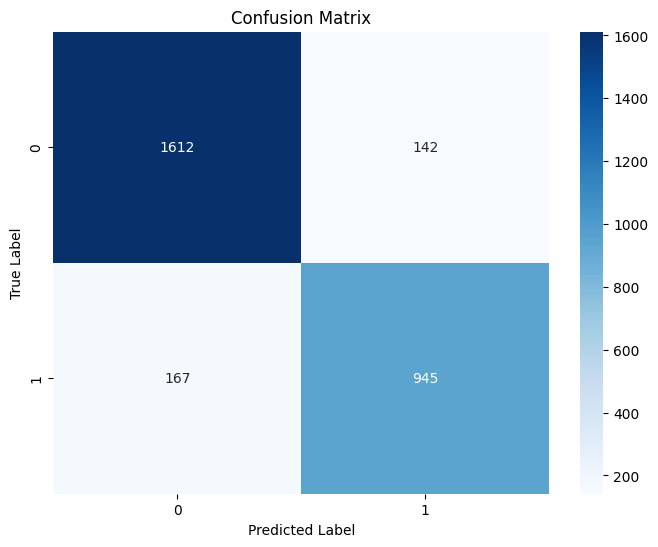

In [30]:
# Evaluation on test set
test_dataset = datasets.ImageFolder(root='/kaggle/input/gluacoma-dataset/glaucoma_dataset/test', transform=test_transform)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

inception.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, targets in test_loader:
        images, targets = images.to(device), targets.to(device)
        outputs = inception(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(targets.cpu().numpy())

# Convert to numpy arrays
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# Metrics
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds, average='weighted')
recall = recall_score(all_labels, all_preds, average='weighted')
f1 = f1_score(all_labels, all_preds, average='weighted')
conf_mat = confusion_matrix(all_labels, all_preds)
report = classification_report(all_labels, all_preds)

print("Test Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("\nClassification Report:\n", report)

# Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# Model Performance Comparison for all models

Model Comparison:

         Model  Accuracy  Precision  Recall  F1 Score
0     ResNet50    0.9574     0.9586  0.9574    0.9571
1     ResNet18    0.9560     0.9568  0.9560    0.9557
2        VGG19    0.8660     0.8655  0.8660    0.8657
3  InceptionV3    0.8922     0.8919  0.8922    0.8920


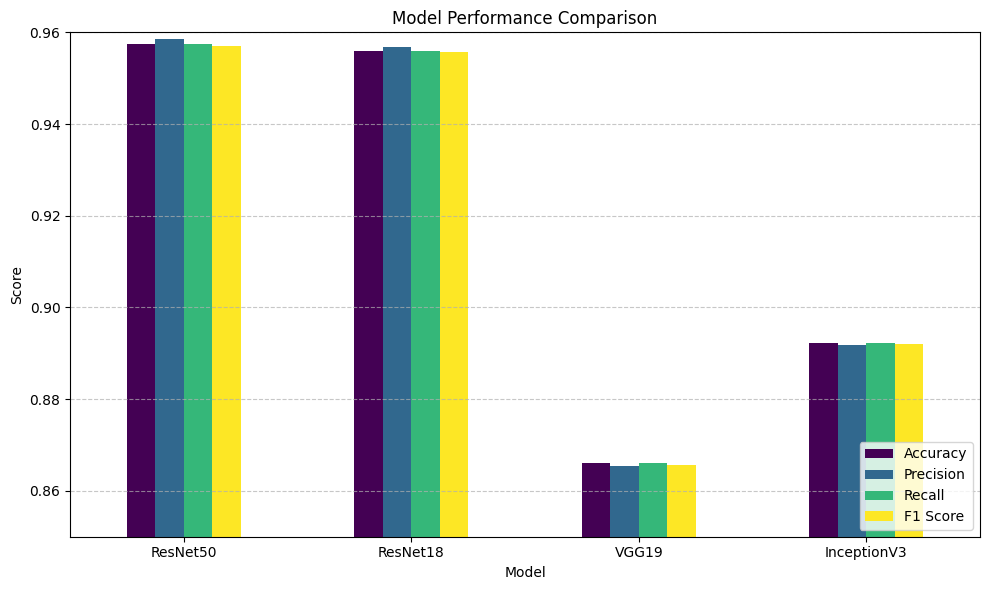

In [31]:
import matplotlib.pyplot as plt
import pandas as pd

# Model performance metrics
data = {
    'Model': ['ResNet50', 'ResNet18', 'VGG19', 'InceptionV3'],
    'Accuracy': [0.9574, 0.9560, 0.8660, 0.8922],
    'Precision': [0.9586, 0.9568, 0.8655, 0.8919],
    'Recall': [0.9574, 0.9560, 0.8660, 0.8922],
    'F1 Score': [0.9571, 0.9557, 0.8657, 0.8920]
}

# Create DataFrame
df = pd.DataFrame(data)

# Display the table
print("Model Comparison:\n")
print(df)

# Plotting
df.set_index('Model').plot(kind='bar', figsize=(10, 6), colormap='viridis')
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0.85, 0.96)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Accuracy Comparison

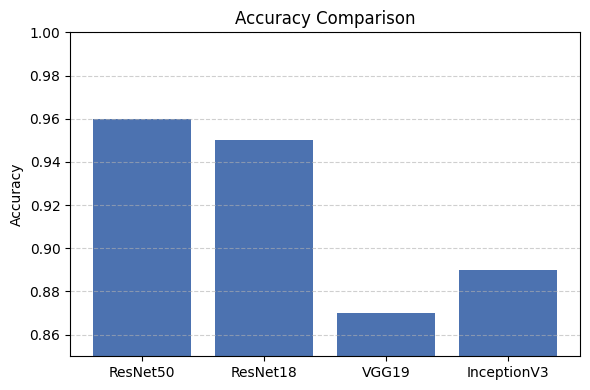

In [38]:
import matplotlib.pyplot as plt

models = ['ResNet50', 'ResNet18', 'VGG19', 'InceptionV3']
accuracy = [0.96, 0.95, 0.87, 0.89]

plt.figure(figsize=(6, 4))
plt.bar(models, accuracy, color='#4c72b0')
plt.title('Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0.85, 1.00)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Precision Comparison

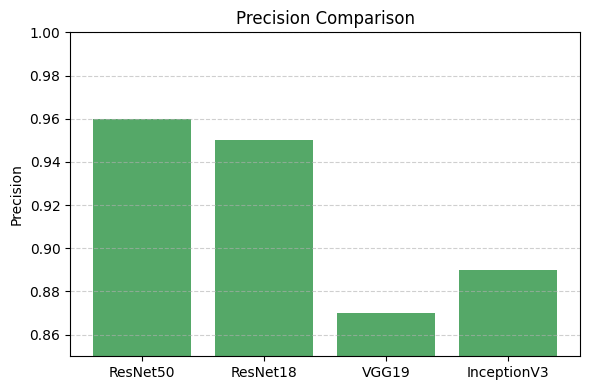

In [39]:
precision = [0.96, 0.95, 0.87, 0.89]

plt.figure(figsize=(6, 4))
plt.bar(models, precision, color='#55a868')
plt.title('Precision Comparison')
plt.ylabel('Precision')
plt.ylim(0.85, 1.00)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Recall Comparison

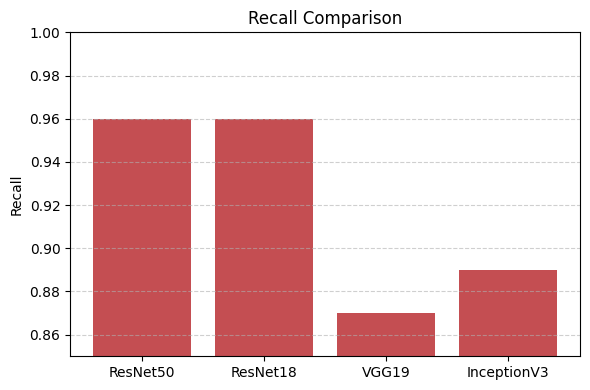

In [40]:
recall = [0.96, 0.96, 0.87, 0.89]

plt.figure(figsize=(6, 4))
plt.bar(models, recall, color='#c44e52')
plt.title('Recall Comparison')
plt.ylabel('Recall')
plt.ylim(0.85, 1.00)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# F1 Score Comparison

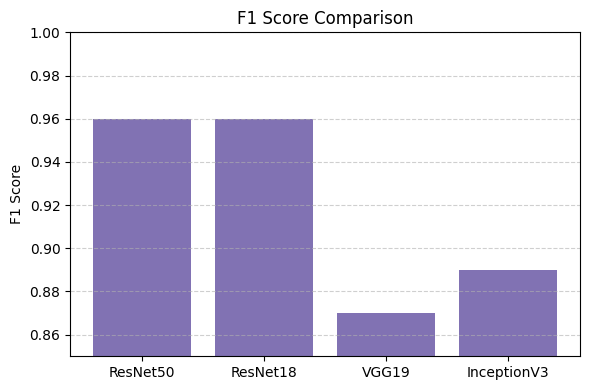

In [36]:
f1_score = [0.96, 0.96, 0.87, 0.89]

plt.figure(figsize=(6, 4))
plt.bar(models, f1_score, color='#8172b3')
plt.title('F1 Score Comparison')
plt.ylabel('F1 Score')
plt.ylim(0.85, 1.00)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

1. **Second stage of the project is to Calculate Cup-to-Disc ratio(CDR) for Glaucoma images**
2. **To calculate CDR we are using YOLOv8 model**

# install ultralytics for Yolo model

In [41]:
!pip install ultralytics --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 993.8/993.8 kB 27.4 MB/s eta 0:00:00:00:01


In [42]:
import os
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


# DataSet preparation for Yolo model

In [43]:
dataset_path = "/kaggle/input/glaucoma-dataset"
# Check if dataset folder exists
if os.path.exists(dataset_path):
    print("Dataset found ✅")
    print("Contents:", os.listdir(dataset_path))
else:
    print("Dataset NOT found ❌")

Dataset found ✅
Contents: ['data.yaml', 'valid', 'test', 'train']


In [44]:
print("Train Images:", os.listdir(f"{dataset_path}/train/images")[:5])  # Show first 5 images
print("Validation Images:", os.listdir(f"{dataset_path}/valid/images")[:5])
print("Test Images:", os.listdir(f"{dataset_path}/test/images")[:5])

Train Images: ['glc212_jpg.rf.c87c11ff9d05262040b8e42f7dd0977a.jpg', 'EyePACS-Glaucoma-357_jpg.rf.78599233aa1a9e821517b92a6339d3fb.jpg', 'REFUGE1-val-394-Copy_jpg.rf.1c34f14d24e8ec221b4afac81c8ad0e3.jpg', 'OIA-ODIR-TRAIN-256_jpg.rf.6c04cbcc788b55d785110ba31ded8a60.jpg', 'REFUGE1-train-27-Copy_jpg.rf.33fdda1f39290576eb4dc1485c539a28.jpg']
Validation Images: ['EyePACS-Glaucoma-2544-Copy_jpg.rf.66387a5a8f58a3050ebe02c080344944.jpg', 'sjchoi86-HRF-197-Copy_jpg.rf.03c4d51a999d17172605ce449d218930.jpg', 'REFUGE1-train-337-Copy_jpg.rf.d00515319f1ce82485df97de7d536812.jpg', 'EyePACS-Glaucoma-1949_jpg.rf.c467602575e1c38720ed8a49649bc55d.jpg', 'glc119_jpg.rf.82f034aa6880c5a71a556f668b82d33f.jpg']
Test Images: ['glc71_jpg.rf.079386c137e909bb909f748d3d692024.jpg', 'glc107_jpg.rf.ab5eb2001ed02bc6e2a80b4e6e5eb10a.jpg', 'OIA-ODIR-TRAIN-3154_jpg.rf.b87399d95ba5b04b6918963f09a64409.jpg', 'EyePACS-Glaucoma-1202_jpg.rf.9abd9ccf87fb64746bedd9131c5fb8f6.jpg', 'glc07_jpg.rf.dc654c10721ce0c9e3d5a2bc0c1b70d9.

# Data Vizuvalizations on Yolo dataset

## Sample images with Optic cup, Optic disc Bounding boxes

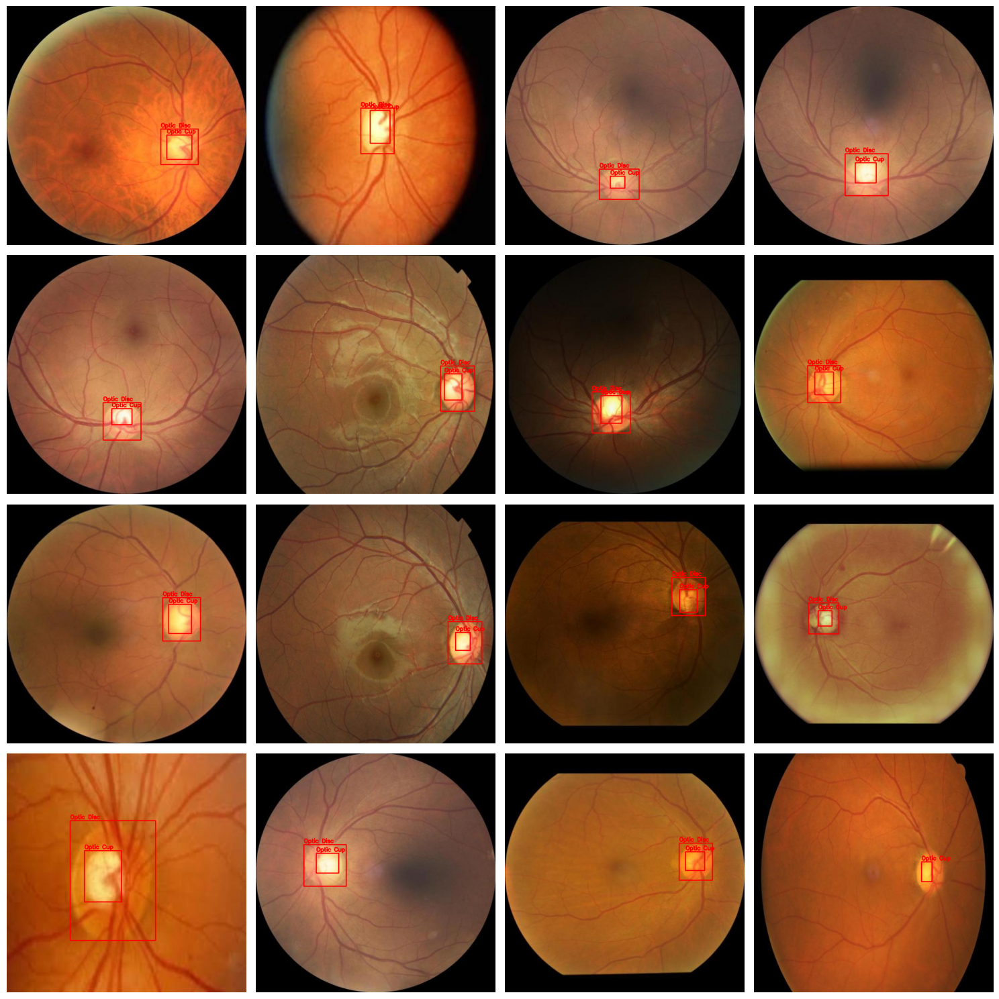

In [45]:
import cv2
import matplotlib.pyplot as plt
import glob
import os
import random

# Function to visualize images with bounding boxes in a 4x4 grid
def plot_images_with_boxes(image_folder, label_folder, class_names, num_images=16, rows=4, cols=4):
    image_paths = random.sample(glob.glob(f"{image_folder}/*.jpg"), min(num_images, len(glob.glob(f"{image_folder}/*.jpg"))))

    fig, axes = plt.subplots(rows, cols, figsize=(15, 15))
    
    for ax, img_path in zip(axes.flat, image_paths):
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        label_path = img_path.replace("images", "labels").replace(".jpg", ".txt")
        
        if os.path.exists(label_path):
            with open(label_path, "r") as file:
                labels = file.readlines()
            
            for label in labels:
                data = label.strip().split()
                class_id, x_center, y_center, width, height = map(float, data)
                
                # Convert YOLO format to pixel values
                img_h, img_w = img.shape[:2]
                x1 = int((x_center - width / 2) * img_w)
                y1 = int((y_center - height / 2) * img_h)
                x2 = int((x_center + width / 2) * img_w)
                y2 = int((y_center + height / 2) * img_h)
                
                # Draw bounding box
                cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
                cv2.putText(img, class_names[int(class_id)], (x1, y1 - 5), 
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)
        
        ax.imshow(img)
        ax.axis("off")
    
    plt.tight_layout()
    plt.show()

# Set paths
train_image_folder = f"{dataset_path}/train/images"
train_label_folder = f"{dataset_path}/train/labels"

# Visualize sample training images with bounding boxes in 4x4 grid
plot_images_with_boxes(train_image_folder, train_label_folder, 
                       ['Optic Cup', 'Optic Disc'], num_images=16, rows=4, cols=4)

## Class Distribution in Training Dataset

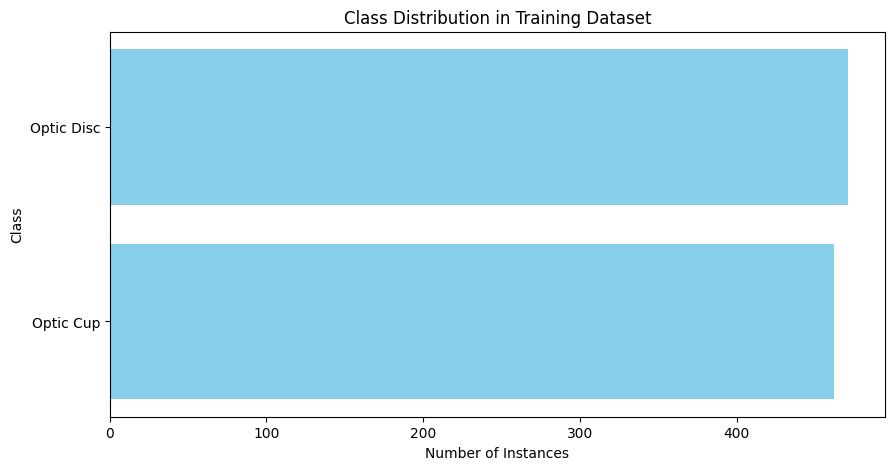

In [46]:
import glob
import pandas as pd
import matplotlib.pyplot as plt

# Read label files and count instances per class
def count_class_instances(label_folder, num_classes=2):
    class_counts = [0] * num_classes
    label_files = glob.glob(f"{label_folder}/*.txt")
    
    for label_file in label_files:
        with open(label_file, "r") as file:
            labels = file.readlines()
            for label in labels:
                class_id = int(label.split()[0])
                class_counts[class_id] += 1
                
    return class_counts

# Specify your label folder path
train_label_folder = '/kaggle/input/glaucoma-dataset/train/labels'

# Count instances assuming there are only 2 classes
train_class_counts = count_class_instances(train_label_folder, num_classes=2)
class_names = ['Optic Cup', 'Optic Disc']

# Create DataFrame
df = pd.DataFrame({"Class": class_names, "Instances": train_class_counts})
df = df.sort_values(by="Instances", ascending=False)

# Plot class distribution
plt.figure(figsize=(10,5))
plt.barh(df["Class"], df["Instances"], color="skyblue")
plt.xlabel("Number of Instances")
plt.ylabel("Class")
plt.title("Class Distribution in Training Dataset")
plt.gca().invert_yaxis()
plt.show()

## Show random images from different classes

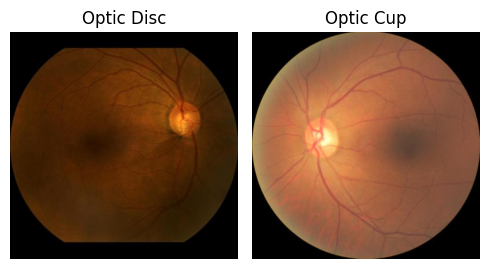

In [47]:
import glob
import random
import cv2
import matplotlib.pyplot as plt

def plot_sample_images_per_class(image_folder, label_folder, class_names, num_classes=16, rows=4, cols=4):
    fig, axes = plt.subplots(rows, cols, figsize=(5, 5))
    selected_classes = random.sample(class_names, min(num_classes, len(class_names)))
    
    for ax, class_name in zip(axes.flat, selected_classes):  
        class_files = glob.glob(f"{label_folder}/*.txt")
        class_images = []
        
        for label_file in class_files:
            with open(label_file, "r") as file:
                labels = file.readlines()
                for label in labels:
                    class_id = int(label.split()[0])
                    if class_names[class_id] == class_name:
                        image_file = label_file.replace("labels", "images").replace(".txt", ".jpg")
                        class_images.append(image_file)
        
        if class_images:
            img_path = random.choice(class_images)
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax.imshow(img)
            ax.set_title(class_name)
        else:
            ax.set_title(f"{class_name} (No Images)")
        
        ax.axis("off")
    
    plt.tight_layout()
    plt.show()

# Show random images from different classes in 4x4 grid
plot_sample_images_per_class(train_image_folder, train_label_folder, class_names, num_classes=2, rows=1, cols=2)

## Bounding Box Size Distribution

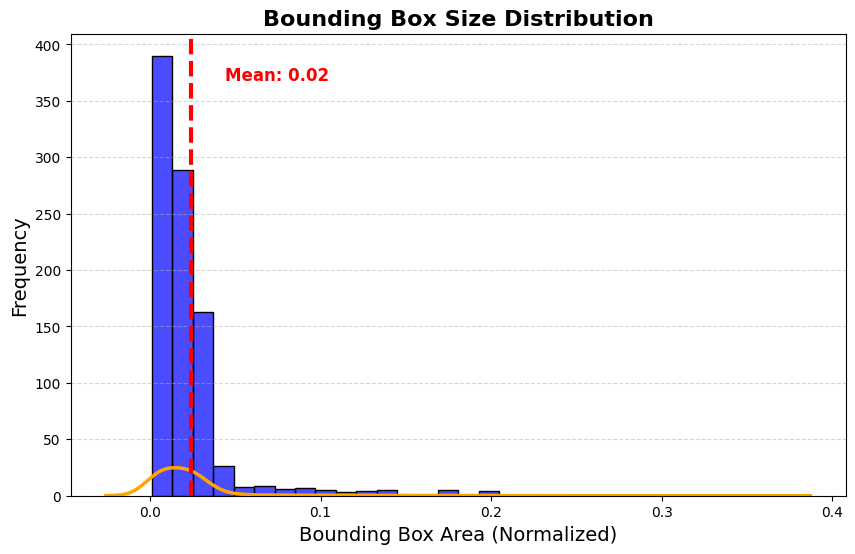

In [48]:
import seaborn as sns
import matplotlib.pyplot as plt
import glob

def plot_bbox_size_distribution(label_folder):
    bbox_sizes = []
    
    label_files = glob.glob(f"{label_folder}/*.txt")
    
    for label_file in label_files:
        with open(label_file, "r") as file:
            labels = file.readlines()
            for label in labels:
                _, _, _, width, height = map(float, label.strip().split())
                bbox_sizes.append(width * height)  # Area of bounding box

    # Create a larger figure
    plt.figure(figsize=(10, 6))

    # Create histogram
    sns.histplot(bbox_sizes, bins=30, color="blue", edgecolor="black", alpha=0.7)

    # Add KDE plot with better visibility
    sns.kdeplot(bbox_sizes, color="orange", linewidth=2.5)

    # Add mean line and annotation
    mean_bbox_size = sum(bbox_sizes) / len(bbox_sizes)
    plt.axvline(mean_bbox_size, color='red', linestyle='dashed', linewidth=3)
    plt.text(mean_bbox_size + 0.02, max(plt.ylim()) * 0.9, 
             f"Mean: {mean_bbox_size:.2f}", color="red", fontsize=12, fontweight="bold")

    # Labels and title
    plt.xlabel("Bounding Box Area (Normalized)", fontsize=14)
    plt.ylabel("Frequency", fontsize=14)
    plt.title("Bounding Box Size Distribution", fontsize=16, fontweight="bold")

    # Improve grid readability
    plt.grid(axis='y', linestyle='--', alpha=0.5)

    # Optional: Use log scale for better small object distribution
    # plt.xscale("log")

    # Show plot
    plt.show()

# Plot bounding box size distribution
plot_bbox_size_distribution(train_label_folder)

## Plot heatmat

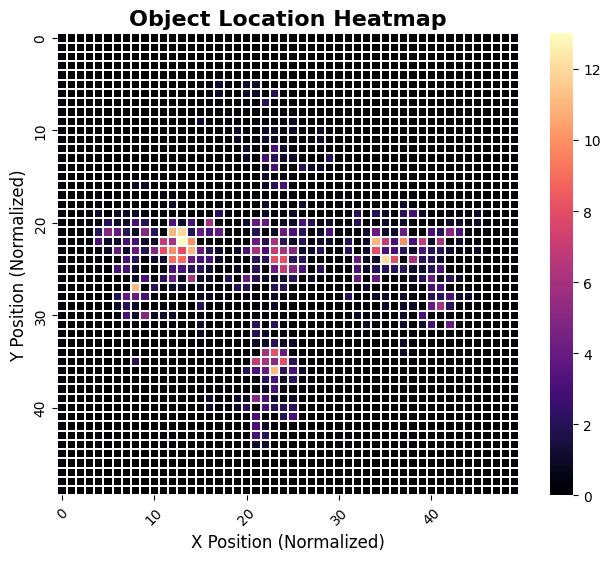

In [49]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import glob

def plot_heatmap(label_folder, img_size=640, grid_size=50):
    heatmap = np.zeros((grid_size, grid_size))  # Reduce resolution for better aggregation
    
    label_files = glob.glob(f"{label_folder}/*.txt")
    
    for label_file in label_files:
        with open(label_file, "r") as file:
            labels = file.readlines()
            for label in labels:
                _, x_center, y_center, _, _ = map(float, label.strip().split())

                # Convert to grid coordinates
                x = int(x_center * (grid_size - 1))
                y = int(y_center * (grid_size - 1))

                heatmap[y, x] += 1  # Increment frequency

    plt.figure(figsize=(8, 6))
    
    # Choose a better colormap for contrast
    sns.heatmap(heatmap, cmap="magma", cbar=True, linewidths=0.1, square=True, 
                xticklabels=10, yticklabels=10)

    # Improve axis readability
    plt.xticks(rotation=45, fontsize=10)
    plt.yticks(fontsize=10)

    # Title & Labels
    plt.title("Object Location Heatmap", fontsize=16, fontweight="bold")
    plt.xlabel("X Position (Normalized)", fontsize=12)
    plt.ylabel("Y Position (Normalized)", fontsize=12)

    plt.show()

# Plot heatmap with improvements
plot_heatmap(train_label_folder)

## Class Distribution in Dataset

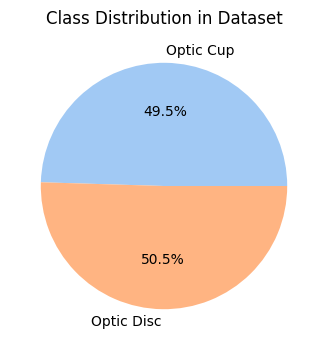

In [50]:
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Read label files and count instances per class
def count_class_instances(label_folder, num_classes=2):
    class_counts = [0] * num_classes
    label_files = glob.glob(f"{label_folder}/*.txt")
    
    for label_file in label_files:
        with open(label_file, "r") as file:
            labels = file.readlines()
            for label in labels:
                class_id = int(label.split()[0])
                class_counts[class_id] += 1
                
    return class_counts

# Specify your label folder path
train_label_folder = '/kaggle/input/glaucoma-dataset/train/labels'  # Update with your actual folder path

# Count instances assuming there are only 2 classes
train_class_counts = count_class_instances(train_label_folder, num_classes=2)
class_names = ['Optic Cup', 'Optic Disc']

# Create a DataFrame (optional)
df = pd.DataFrame({"Class": class_names, "Instances": train_class_counts})
df = df.sort_values(by="Instances", ascending=False)

# Plot the class distribution as a pie chart
plt.figure(figsize=(4, 4))
plt.pie(train_class_counts, labels=class_names, autopct='%1.1f%%', colors=sns.color_palette("pastel"))
plt.title("Class Distribution in Dataset")
plt.show()

## Distribution of Objects per Image

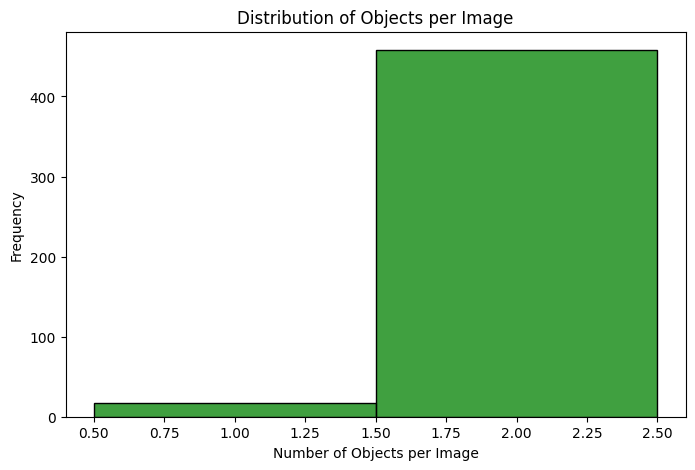

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns
import glob

def plot_avg_objects_per_image(label_folder):
    num_objects = []
    
    label_files = glob.glob(f"{label_folder}/*.txt")
    
    for label_file in label_files:
        with open(label_file, "r") as file:
            labels = file.readlines()
            num_objects.append(len(labels))  

    plt.figure(figsize=(8, 5))
    
    # Plot histogram without KDE
    sns.histplot(num_objects, bins=range(1, max(num_objects)+2), color="green", discrete=True)

    plt.xlabel("Number of Objects per Image")
    plt.ylabel("Frequency")
    plt.title("Distribution of Objects per Image")
    plt.show()

# Run the function again
plot_avg_objects_per_image(train_label_folder)

In [52]:
data_yaml = """train: /kaggle/input/glaucoma-dataset/train/images
val: /kaggle/input/glaucoma-dataset/valid/images
test: /kaggle/input/glaucoma-dataset/test/images

nc: 2
names: ['Optic Cup', 'Optic Disc']
"""

# Save the YAML file inside the working directory
yaml_path = "/kaggle/working/data.yaml"
with open(yaml_path, "w") as f:
    f.write(data_yaml)

print(f"data.yaml file saved at: {yaml_path}")

data.yaml file saved at: /kaggle/working/data.yaml


# Train the YOLOv8 model

In [53]:
from ultralytics import YOLO
import torch

# Check GPU availability
device = 0 if torch.cuda.is_available() else 'cpu'

# Load YOLOv8 nano model
model = YOLO("yolov8n.pt")  

# Train the model
model.train(
    data="/kaggle/working/data.yaml",  # Corrected path to dataset config
    epochs=50,          # Number of training epochs
    imgsz=640,          # Image size
    batch=16,           # Batch size
    device=device,      # Auto-select GPU or CPU
    save=True           # Save model weights
)

100%|██████████| 6.25M/6.25M [00:00<00:00, 295MB/s]

Ultralytics 8.3.102 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: task=detect, mode=train, model=yolov8n.pt, data=/kaggle/working/data.yaml, epochs=50, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=False, show_labels=True, show_conf=True, s

100%|██████████| 755k/755k [00:00<00:00, 104MB/s]


Overriding model.yaml nc=80 with nc=2

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             
  3                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  4                  -1  2     49664  ultralytics.nn.modules.block.C2f             [64, 64, 2, True]             
  5                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  6                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  7                  -1  1    295424  ultralytics

100%|██████████| 5.35M/5.35M [00:00<00:00, 324MB/s]


...

                   all        136        269      0.981      0.972      0.983        0.7



50 epochs completed in 0.092 hours.
Optimizer stripped from runs/detect/train/weights/last.pt, 6.2MB
Optimizer stripped from runs/detect/train/weights/best.pt, 6.2MB

Validating runs/detect/train/weights/best.pt...
Ultralytics 8.3.102 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
Model summary (fused): 72 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 5/5 [00:01<00:00,  3.00it/s]


                   all        136        269       0.97       0.97      0.979      0.709
             Optic Cup        133        133      0.947      0.947      0.963      0.562
            Optic Disc        136        136      0.993      0.993      0.994      0.855
Speed: 0.2ms preprocess, 2.1ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to runs/detect/train


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b0f98c40940>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

# Evaluate the trained Model

In [54]:
# Run validation
metrics = model.val()
print(metrics)

Ultralytics 8.3.102 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
Model summary (fused): 72 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs


val: Scanning /kaggle/input/glaucoma-dataset/valid/labels... 136 images, 0 backgrounds, 0 corrupt: 100%|██████████| 136/136 [00:00<00:00, 410.57it/s]

val: WARNING ⚠️ Cache directory /kaggle/input/glaucoma-dataset/valid is not writeable, cache not saved.



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 9/9 [00:02<00:00,  3.91it/s]


                   all        136        269      0.973      0.974      0.982      0.709
             Optic Cup        133        133      0.954      0.955      0.969      0.563
            Optic Disc        136        136      0.993      0.993      0.995      0.854
Speed: 2.1ms preprocess, 3.6ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to runs/detect/train2
ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b0f6117d2a0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,    

# Save the Trained YOLOv8 model

In [55]:
# Save the trained model weights
saved_model_path = "/kaggle/working/glaucoma_detection_yolov8model.pt"
model.export(format="torchscript")  # Save in TorchScript format
model.save(saved_model_path)  # Save the trained model

print(f"Trained model saved at: {saved_model_path}")

Ultralytics 8.3.102 🚀 Python-3.10.12 torch-2.5.1+cu121 CPU (Intel Xeon 2.00GHz)

PyTorch: starting from 'runs/detect/train/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 6, 8400) (6.0 MB)

TorchScript: starting export with torch 2.5.1+cu121...
TorchScript: export success ✅ 1.7s, saved as 'runs/detect/train/weights/best.torchscript' (11.9 MB)

Export complete (3.2s)
Results saved to /kaggle/working/runs/detect/train/weights
Predict:         yolo predict task=detect model=runs/detect/train/weights/best.torchscript imgsz=640  
Validate:        yolo val task=detect model=runs/detect/train/weights/best.torchscript imgsz=640 data=/kaggle/working/data.yaml  
Visualize:       https://netron.app
Trained model saved at: /kaggle/working/glaucoma_detection_yolov8model.pt


# Vizuvalize some sample images with pre-trained yolo model

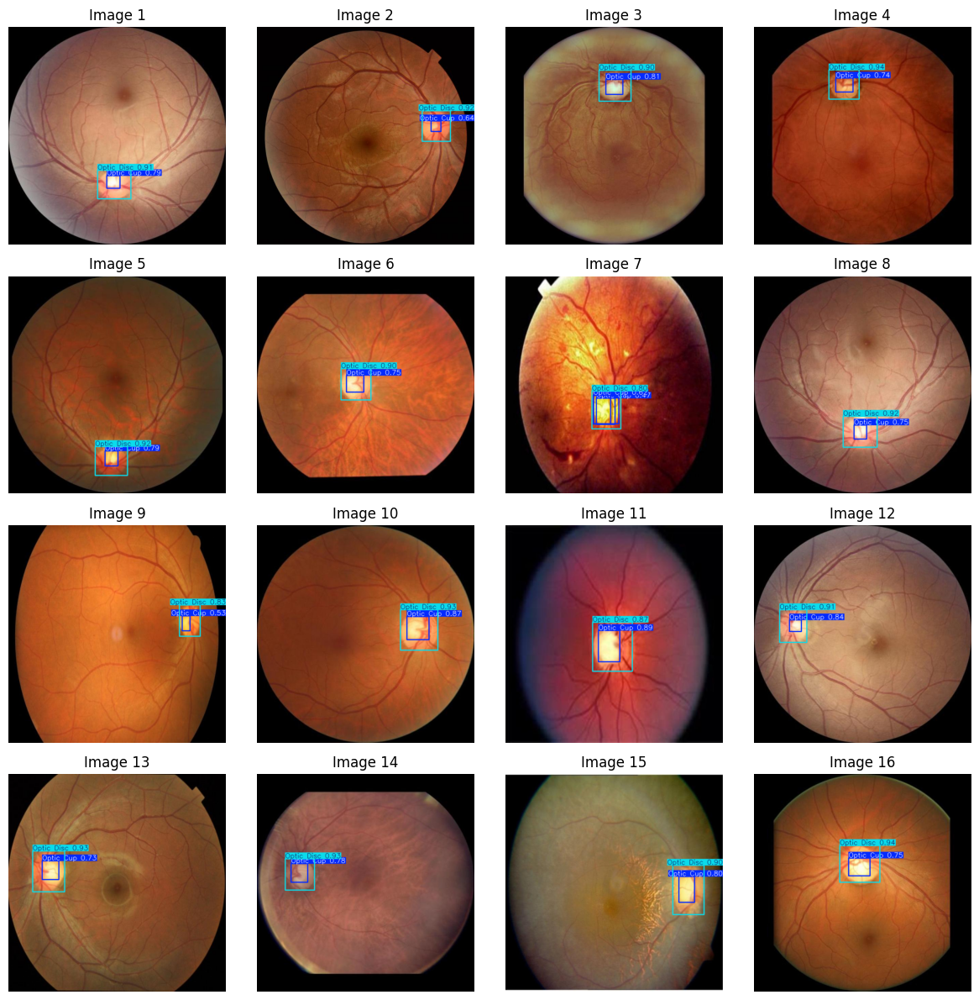

In [56]:
import random
import cv2
import matplotlib.pyplot as plt
from glob import glob

# Get all test images
test_image_dir = f"{dataset_path}/test/images"
test_images = glob(f"{test_image_dir}/*.jpg")  # Adjust extension if needed

# Randomly select 16 images to process
selected_images = random.sample(test_images, min(16, len(test_images)))  

# Run inference on selected images
results = model.predict(source=selected_images, conf=0.25, save=False, verbose=False)  # Turn off detailed logs

# Display results inline
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
axes = axes.flatten()

for i, (result, img_path) in enumerate(zip(results, selected_images)):
    img = result.plot()  # Get the image with detections
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB for Matplotlib

    axes[i].imshow(img)
    axes[i].axis("off")
    axes[i].set_title(f"Image {i+1}")

# Hide unused subplots
for j in range(i + 1, 16):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

# Give Unseen image path as a Input , it will detect the Optic cup and Optic disc in image


image 1/1 /kaggle/input/glaucoma-dataset/test/images/1ffa9639-8d87-11e8-9daf-6045cb817f5b-_jpg.rf.429f9416649a0e7a1f80fcba23d2758c.jpg: 640x640 1 Optic Cup, 1 Optic Disc, 6.1ms
Speed: 1.5ms preprocess, 6.1ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


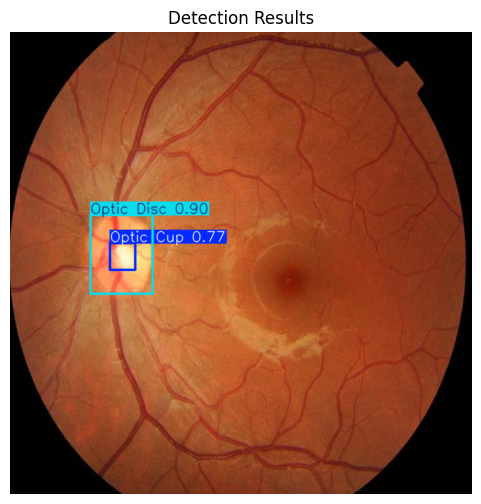

In [57]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Load your custom YOLOv8 model
model_path = "/kaggle/input/gluacoma/pytorch/default/1/glaucoma_detection_yolov8model.pt"
model = YOLO(model_path)

def predict_and_show(img_path):
    # Run inference on the image
    results = model(img_path)
    
    # Render the detection results on the image
    annotated_img = results[0].plot()  # Get annotated image
    
    # Display the annotated image using matplotlib (convert BGR to RGB)
    plt.figure(figsize=(6, 6))
    plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
    plt.title("Detection Results")
    plt.axis("off")
    plt.show()
    
    # Do not print the results object if you want to show only the image.
    # return results  # (Optional: you can return results if needed, but don't print them)

# Replace with your test image path
test_img_path = "/kaggle/input/glaucoma-dataset/test/images/1ffa9639-8d87-11e8-9daf-6045cb817f5b-_jpg.rf.429f9416649a0e7a1f80fcba23d2758c.jpg"

# Run prediction and display only the image
predict_and_show(test_img_path)

# Give Unseen image path as a Input , it will detect the Optic cup and Optic disc in image and Calculates CDR


image 1/1 /kaggle/input/gluacoma-dataset/glaucoma_dataset/test/1/BEH-109.png: 640x640 1 Optic Cup, 1 Optic Disc, 6.0ms
Speed: 2.6ms preprocess, 6.0ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


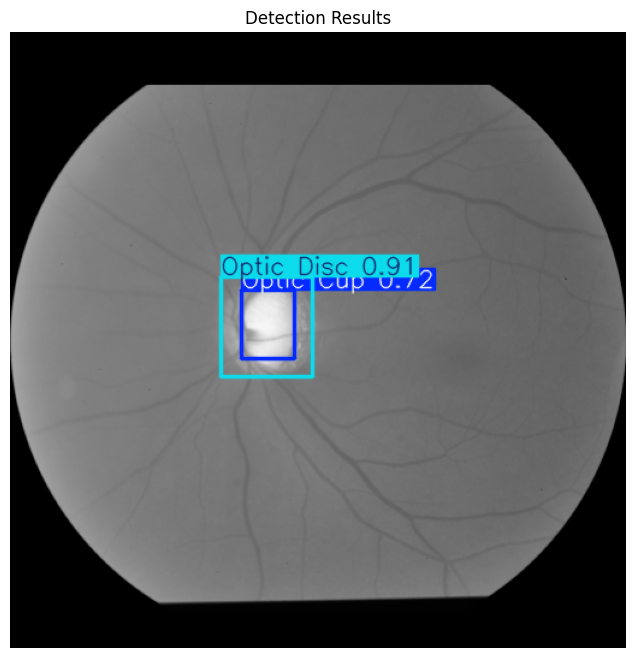

Vertical CDR: 0.691
Glaucoma Severity: Moderate (CDR >= 0.5 and < 0.8)


In [58]:
import cv2
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO
import numpy as np

# ---------------------------
# 1. Load the YOLOv8 Model
# ---------------------------
model_path = "/kaggle/input/gluacoma/pytorch/default/1/glaucoma_detection_yolov8model.pt"
model = YOLO(model_path)

# ---------------------------
# 2. Define Functions for CDR Calculation and Classification
# ---------------------------

def calculate_cdr(image_path):
    """
    Run inference on the image using the YOLOv8 model and calculate the cup-to-disc ratios.
    
    Assumptions:
      - Class 0: Optic Cup
      - Class 1: Optic Disc
    Returns:
      vertical_cdr, horizontal_cdr, average_cdr, results
    """
    # Run inference on the input image
    results = model(image_path)
    
    cup_box = None
    disc_box = None
    
    # Loop through detected boxes (assume one cup and one disc)
    for box in results[0].boxes:
        cls_id = int(box.cls[0].item())  # Class index: 0 for cup, 1 for disc
        xyxy = box.xyxy[0].cpu().numpy()  # Bounding box in [x1, y1, x2, y2] format
        x1, y1, x2, y2 = xyxy
        width = x2 - x1
        height = y2 - y1
        
        if cls_id == 0:  # Optic Cup
            cup_box = (x1, y1, x2, y2, width, height)
        elif cls_id == 1:  # Optic Disc
            disc_box = (x1, y1, x2, y2, width, height)
    
    # Calculate ratios if both boxes were detected
    if cup_box is not None and disc_box is not None:
        cup_w, cup_h = cup_box[4], cup_box[5]
        disc_w, disc_h = disc_box[4], disc_box[5]
        
        vertical_cdr = cup_h / disc_h
        horizontal_cdr = cup_w / disc_w
        average_cdr = (vertical_cdr + horizontal_cdr) / 2
        
        return vertical_cdr, horizontal_cdr, average_cdr, results
    else:
        return None, None, None, results

def classify_glaucoma(cdr):
    """
    Classify glaucoma severity based on vertical CDR.
    
    Criteria:
      - Normal: CDR <= 0.3
      - Mild:   CDR > 0.3 and < 0.5
      - Moderate: CDR >= 0.5 and < 0.8
      - Severe: CDR >= 0.8
    """
    if cdr <= 0.3:
        return "Normal (CDR <= 0.3)"
    elif 0.3 < cdr < 0.5:
        return "Mild (CDR > 0.3 and < 0.5)"
    elif 0.5 <= cdr < 0.8:
        return "Moderate (CDR >= 0.5 and < 0.8)"
    elif cdr >= 0.8:
        return "Severe (CDR >= 0.8)"
    else:
        return "Undefined"

# ---------------------------
# 3. Run Inference and Compute CDR on an Unseen Image
# ---------------------------
test_image_path = "/kaggle/input/gluacoma-dataset/glaucoma_dataset/test/1/BEH-109.png"

v_cdr, h_cdr, avg_cdr, results = calculate_cdr(test_image_path)

# Display the annotated image (bounding boxes with labels)
annotated_img = results[0].plot()  # Returns annotated image in BGR format
plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
plt.title("Detection Results")
plt.axis("off")
plt.show()

# ---------------------------
# 4. Print the Final Cup-to-Disc Ratio and Glaucoma Severity
# ---------------------------
if v_cdr is not None:
    severity = classify_glaucoma(v_cdr)
    print(f"Vertical CDR: {v_cdr:.3f}")
    print(f"Glaucoma Severity: {severity}")
else:
    print("Could not detect the optic cup and disc in the image.")

1. **Classification: Uses a ResNet50 model to classify the input image as either "Glaucoma" or "No Glaucoma".**
2. **Detection & CDR Calculation: If the image is classified as "Glaucoma", it loads a YOLOv8 model to detect the optic cup and disc and calculates the vertical cup-to-disc ratio (CDR) along with a glaucoma severity classification.**

Enter the image path:  /kaggle/input/glaucoma-dataset/test/images/BEH-154_jpg.rf.7ae8de02610044739bae14d428aabcae.jpg


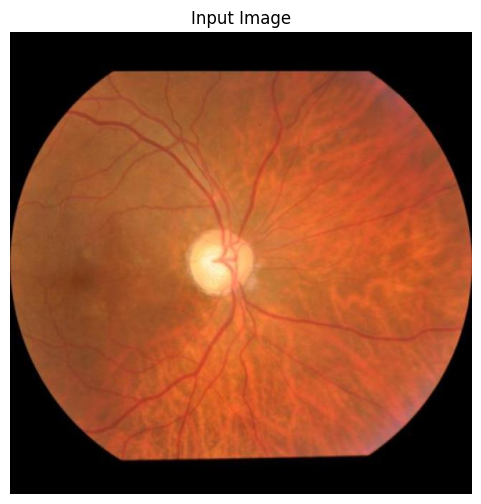

ResNet50 Prediction: Glaucoma

Glaucoma detected. Proceeding with YOLO detection and CDR calculation...


image 1/1 /kaggle/input/glaucoma-dataset/test/images/BEH-154_jpg.rf.7ae8de02610044739bae14d428aabcae.jpg: 640x640 1 Optic Cup, 1 Optic Disc, 6.0ms
Speed: 1.7ms preprocess, 6.0ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


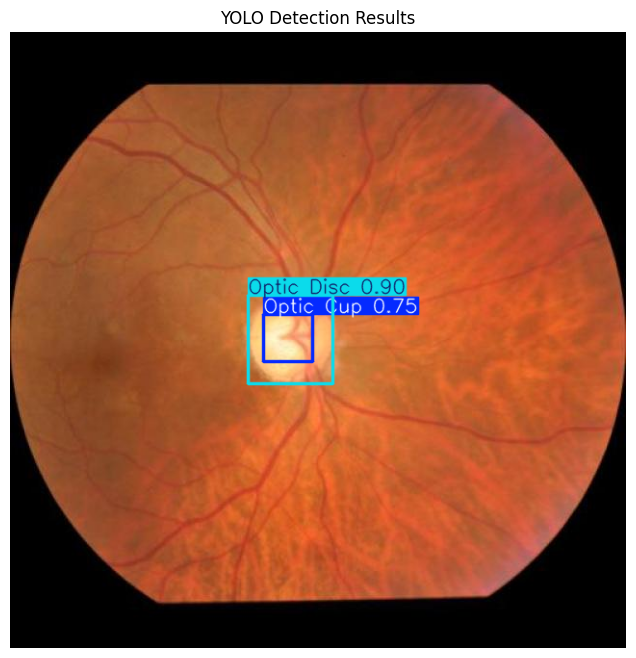

Vertical CDR: 0.536
Glaucoma Severity: Moderate (CDR >= 0.5 and < 0.8)


In [60]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
import cv2
import numpy as np
from ultralytics import YOLO

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------------------
# Step 1: Classification with ResNet50
# ---------------------------

# Define transformation for classification (must match training)
cls_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

# Prompt user for image path
img_path = input("Enter the image path: ")

# Load and display the image
img = Image.open(img_path).convert("RGB")
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.title("Input Image")
plt.axis("off")
plt.show()

# Apply transformation and add batch dimension for classification
img_tensor = cls_transform(img).unsqueeze(0).to(device)

# Recreate the ResNet50 architecture (must match training)
num_classes = 2  # Assuming two classes: "No Glaucoma" and "Glaucoma"
resnet50 = models.resnet50(pretrained=False)
resnet50.fc = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(resnet50.fc.in_features, num_classes)
)
resnet50 = resnet50.to(device)

# Load the saved ResNet50 model state
resnet_model_path = '/kaggle/input/gluacoma/pytorch/default/1/resnet50_final.pth'
checkpoint = torch.load(resnet_model_path, map_location=device)
resnet50.load_state_dict(checkpoint['model_state_dict'])
resnet50.eval()

# Make a prediction using ResNet50
with torch.no_grad():
    outputs = resnet50(img_tensor)
    _, predicted = torch.max(outputs, 1)

# Define class mapping for classification
cls_mapping = {0: "No Glaucoma", 1: "Glaucoma"}
prediction_label = cls_mapping[predicted.item()]
print("ResNet50 Prediction:", prediction_label)

# ---------------------------
# Step 2: If Glaucoma, Run YOLO for Detection & CDR Calculation
# ---------------------------
if prediction_label == "Glaucoma":
    print("\nGlaucoma detected. Proceeding with YOLO detection and CDR calculation...\n")
    
    # Load the YOLOv8 model (for detection)
    yolo_model_path = "/kaggle/input/gluacoma/pytorch/default/1/glaucoma_detection_yolov8model.pt"
    yolo_model = YOLO(yolo_model_path)
    
    def calculate_cdr(image_path):
        """
        Run YOLO inference on the image and calculate the cup-to-disc ratios.
        Assumptions:
          - Class 0: Optic Cup
          - Class 1: Optic Disc
        Returns:
          vertical_cdr, horizontal_cdr, average_cdr, results
        """
        results = yolo_model(image_path)
        cup_box = None
        disc_box = None
        
        # Loop through detected boxes (assume one cup and one disc)
        for box in results[0].boxes:
            cls_id = int(box.cls[0].item())  # 0 for cup, 1 for disc
            xyxy = box.xyxy[0].cpu().numpy()  # [x1, y1, x2, y2]
            x1, y1, x2, y2 = xyxy
            width = x2 - x1
            height = y2 - y1
            
            if cls_id == 0:  # Optic Cup
                cup_box = (x1, y1, x2, y2, width, height)
            elif cls_id == 1:  # Optic Disc
                disc_box = (x1, y1, x2, y2, width, height)
        
        if cup_box is not None and disc_box is not None:
            cup_w, cup_h = cup_box[4], cup_box[5]
            disc_w, disc_h = disc_box[4], disc_box[5]
            vertical_cdr = cup_h / disc_h
            horizontal_cdr = cup_w / disc_w
            average_cdr = (vertical_cdr + horizontal_cdr) / 2
            return vertical_cdr, horizontal_cdr, average_cdr, results
        else:
            return None, None, None, results

    def classify_glaucoma(cdr):
        """
        Classify glaucoma severity based on vertical CDR.
        Criteria:
          - Normal: CDR <= 0.3
          - Mild:   CDR > 0.3 and < 0.5
          - Moderate: CDR >= 0.5 and < 0.8
          - Severe: CDR >= 0.8
        """
        if cdr <= 0.3:
            return "Normal (CDR <= 0.3)"
        elif 0.3 < cdr < 0.5:
            return "Mild (CDR > 0.3 and < 0.5)"
        elif 0.5 <= cdr < 0.8:
            return "Moderate (CDR >= 0.5 and < 0.8)"
        elif cdr >= 0.8:
            return "Severe (CDR >= 0.8)"
        else:
            return "Undefined"

    # Use the same image path for YOLO detection
    v_cdr, h_cdr, avg_cdr, yolo_results = calculate_cdr(img_path)
    
    # Display the annotated image from YOLO (bounding boxes with labels)
    annotated_img = yolo_results[0].plot()  # Annotated image in BGR format
    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
    plt.title("YOLO Detection Results")
    plt.axis("off")
    plt.show()
    
    # Print the CDR values and severity classification based on vertical CDR
    if v_cdr is not None:
        severity = classify_glaucoma(v_cdr)
        print(f"Vertical CDR: {v_cdr:.3f}")
        print(f"Glaucoma Severity: {severity}")
    else:
        print("Could not detect both the optic cup and disc for CDR calculation.")
else:
    print("\nNo Glaucoma detected. Skipping YOLO detection and CDR calculation.")

# **THANK YOU**